In [172]:
import scanpy as sc
import pandas as pd
import numpy as np
import sys
import random

sys.path.append("../../mapqc/")
import mapqc
import plotting

In [ ]:
import warnings

warnings.filterwarnings("ignore")

In [2]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

In [168]:
sc.set_figure_params(figsize=(5, 5))

read in mapqc results:

In [4]:
results_healthy = mapqc.load("./HECA_results_healthy.pkl")
results_disease = mapqc.load("./HECA_results_disease.pkl")

read in embedding with mapped query:

In [5]:
adata_emb = sc.read_h5ad(
    "../../data/HECA/queries_mapped/Asherman_syndrome_mapped_emb_subsetted_and_processed.h5ad"
)

shuffle row order emb for plotting:

In [177]:
shuffled_idc = adata_emb.obs.index.tolist()
random.shuffle(shuffled_idc)
adata_emb = adata_emb[shuffled_idc, :].copy()

add mapQC results to embedding with both healthy and diseased:

In [234]:
for stat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
]:
    adata_emb.obs[stat] = np.nan
    healthy_idc = [
        idx for idx in adata_emb.obs.index if idx in results_healthy.adata.obs.index
    ]
    adata_emb.obs.loc[healthy_idc, stat] = results_healthy.adata.obs.loc[
        healthy_idc, stat
    ]
    disease_idc = [
        idx for idx in adata_emb.obs.index if idx in results_disease.adata.obs.index
    ]
    adata_emb.obs.loc[disease_idc, stat] = results_disease.adata.obs.loc[
        disease_idc, stat
    ]

add updated UMAPs to mapqc results (these still have umaps based on reference including both healthy and disease, we are working with only healthy from the reference. UMAP was calculated in notebook #3)

In [6]:
results_healthy.adata.obsm["X_umap"] = adata_emb[
    results_healthy.adata.obs.index, :
].obsm["X_umap"]
results_healthy._adata_ordered.obsm["X_umap"] = adata_emb[
    results_healthy._adata_ordered.obs.index, :
].obsm["X_umap"]
results_disease.adata.obsm["X_umap"] = adata_emb[
    results_disease.adata.obs.index, :
].obsm["X_umap"]
results_disease._adata_ordered.obsm["X_umap"] = adata_emb[
    results_disease._adata_ordered.obs.index, :
].obsm["X_umap"]

read in raw reference data in backed mode:

In [7]:
adata_full = sc.read_h5ad(
    "../../data/HECA/queries_counts/HECA_ref_plus_Santamaria_query.h5ad", backed="r"
)

In [8]:
adata_emb

AnnData object with n_obs × n_vars = 227735 × 10
    obs: 'n_genes', 'sample', 'library', 'Processing', 'Treatment', '10x kit', 'percent_mito', 'n_counts', 'scrublet_score', 'genotype', 'Library_genotype', 'Group', 'Endometriosis_stage', 'Hormonal treatment', 'Binary Stage', 'Stage', 'phase', 'dataset', 'Biopsy_type', 'Tissue_sampled', 'Age', 'Endometrial_pathology', 'celltype', 'lineage', 'label_long', '_scvi_batch', '_scvi_labels', 'nCount_RNA', 'nFeature_RNA', 'mitochondria_ratio', 'menstrual_cycle_day', 'principal_cell_types', 'batch', 'ref_or_query', 'leiden'
    uns: 'dataset_colors', 'neighbors', 'umap'
    obsm: 'X_umap'
    obsp: 'connectivities', 'distances'

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


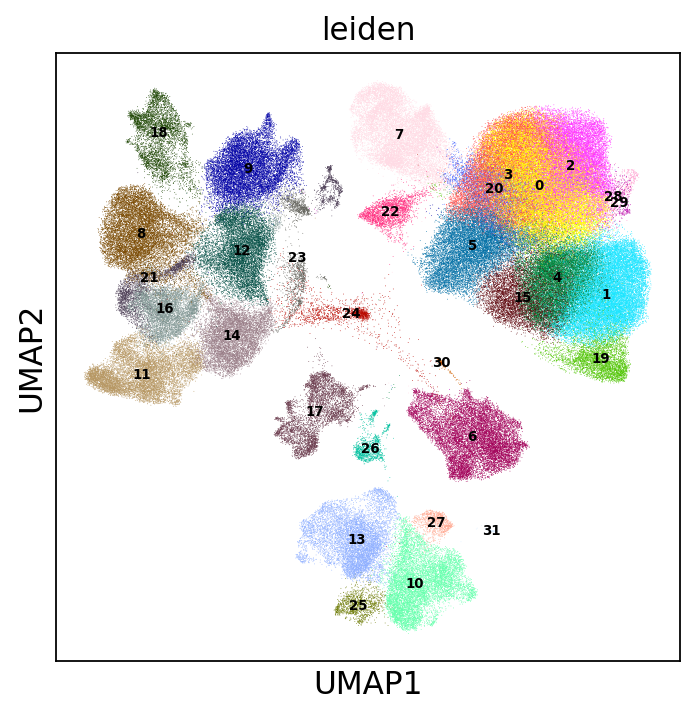

In [9]:
sc.pl.umap(adata_emb, color=["leiden"], legend_loc="on data", legend_fontsize=6)

### Visualize mapQC results on controls:

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


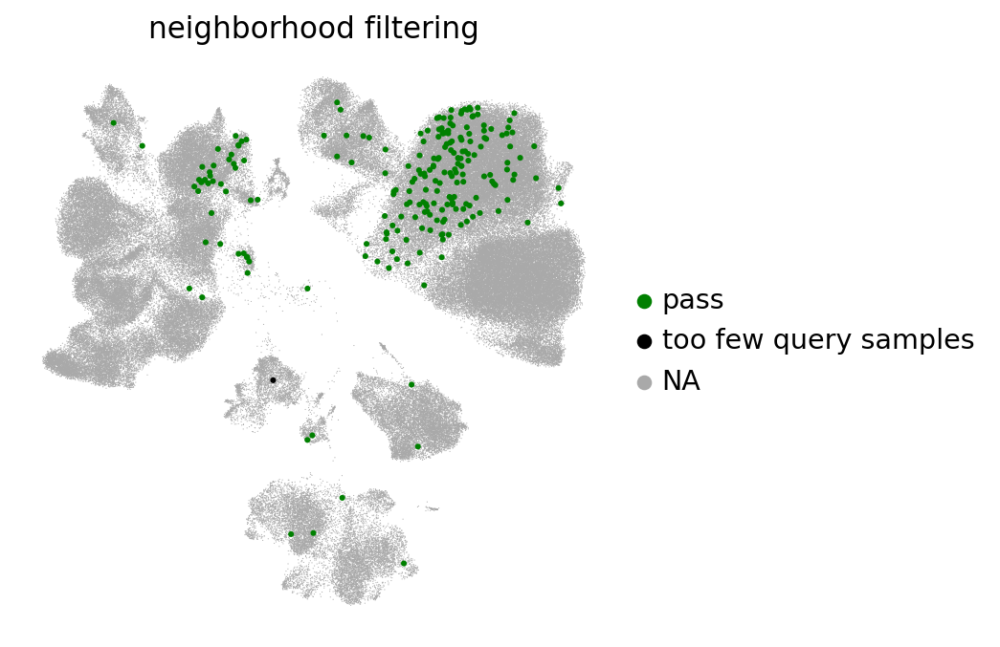

In [10]:
plotting.plot_umap_filtering_info(results_healthy)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


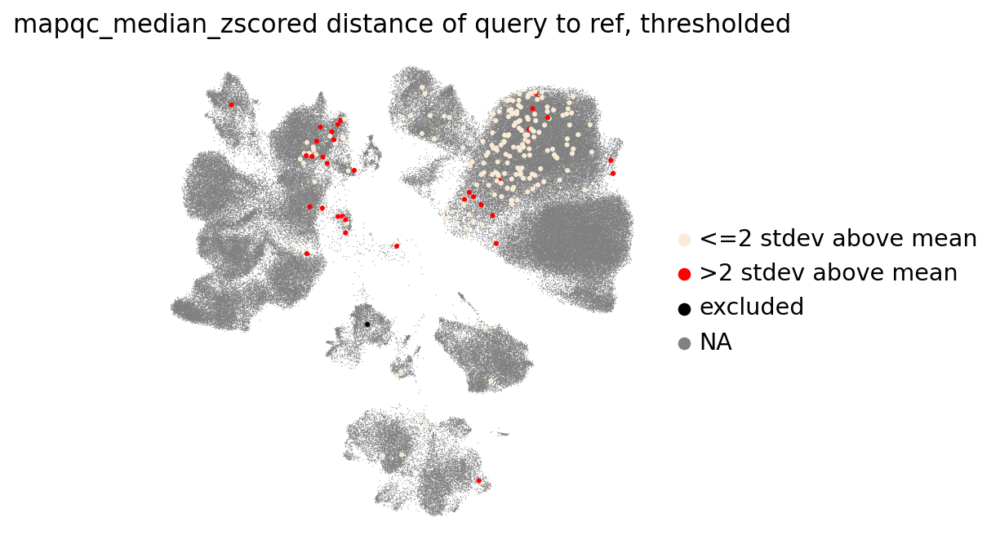

In [11]:
plotting.plot_umap_zscored_q_dist_to_ref(results_healthy, color_by="median_zscore>2")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


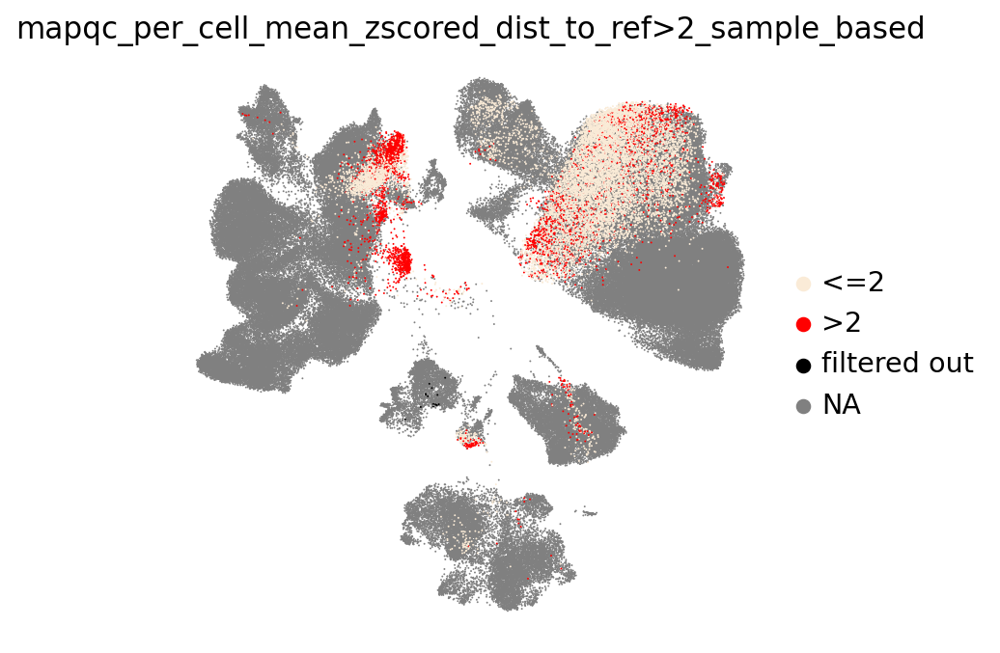

In [12]:
plotting.plot_umap_cell_level_results(results_healthy, size=3)

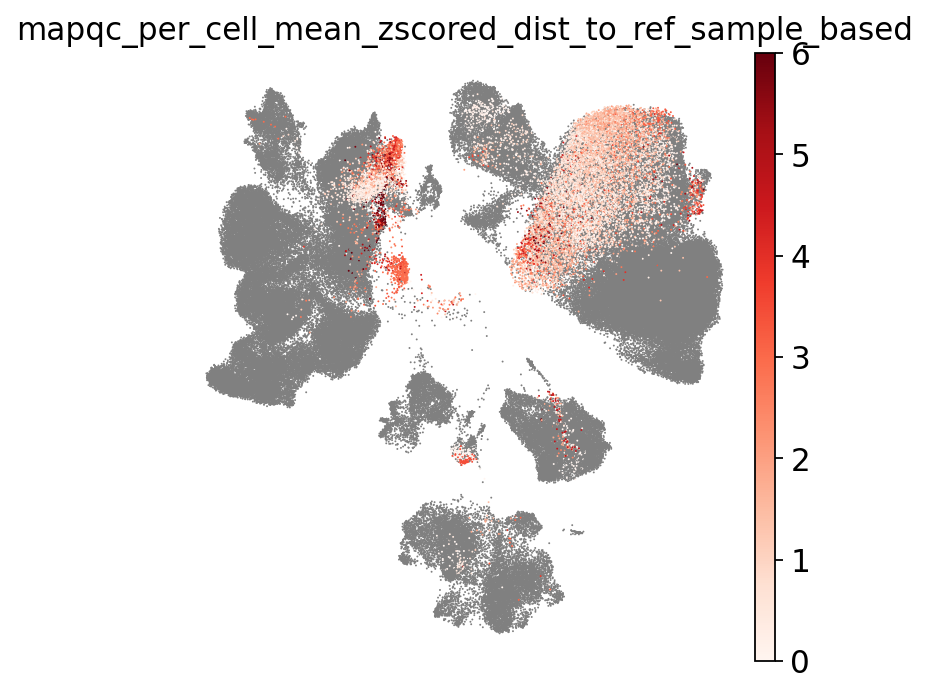

In [232]:
plotting.plot_umap_cell_level_results(
    results_healthy, size=3, color_by="zscore", vmin=0, vmax=6
)

### Visualize results disease:

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


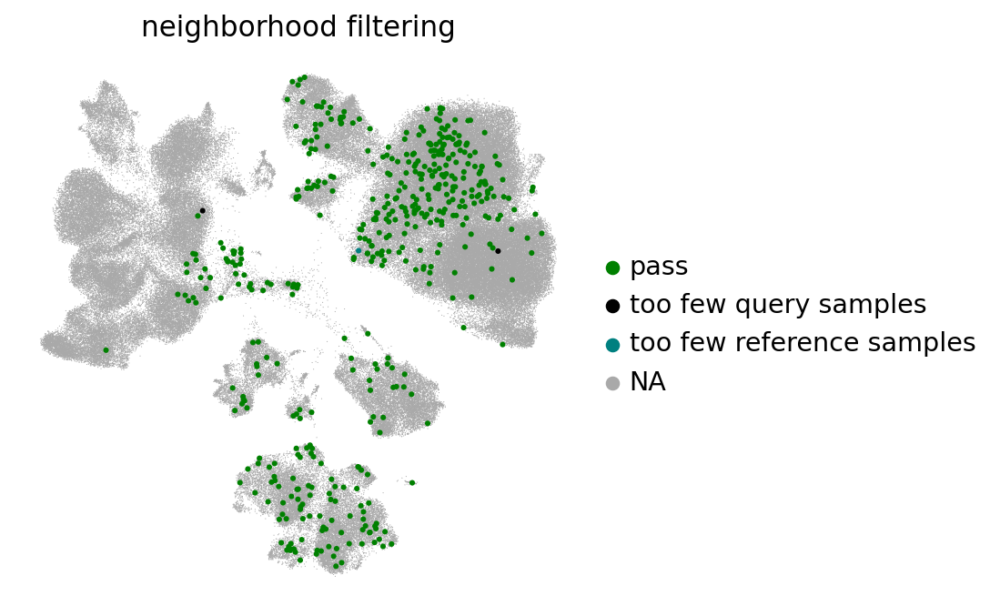

In [13]:
plotting.plot_umap_filtering_info(results_disease)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


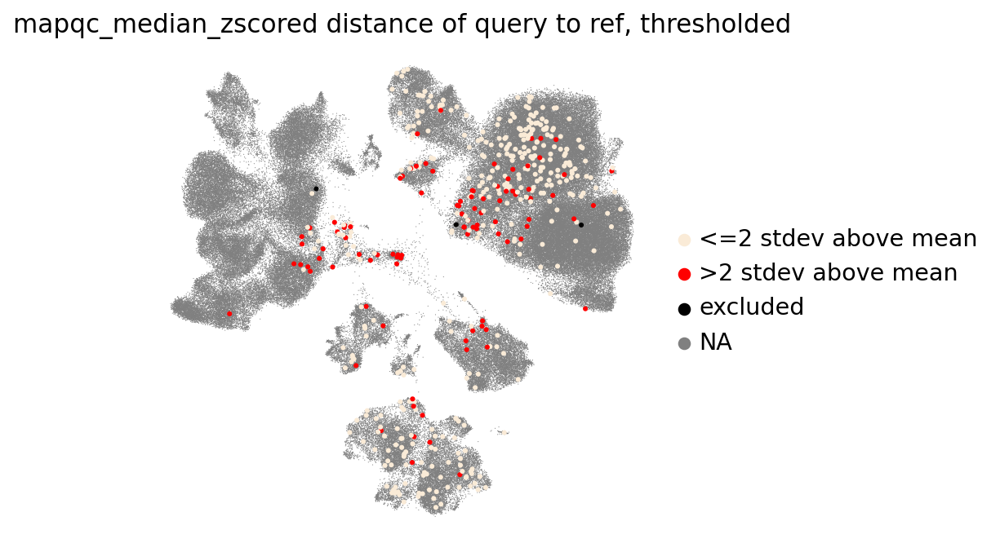

In [14]:
plotting.plot_umap_zscored_q_dist_to_ref(results_disease, color_by="median_zscore>2")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


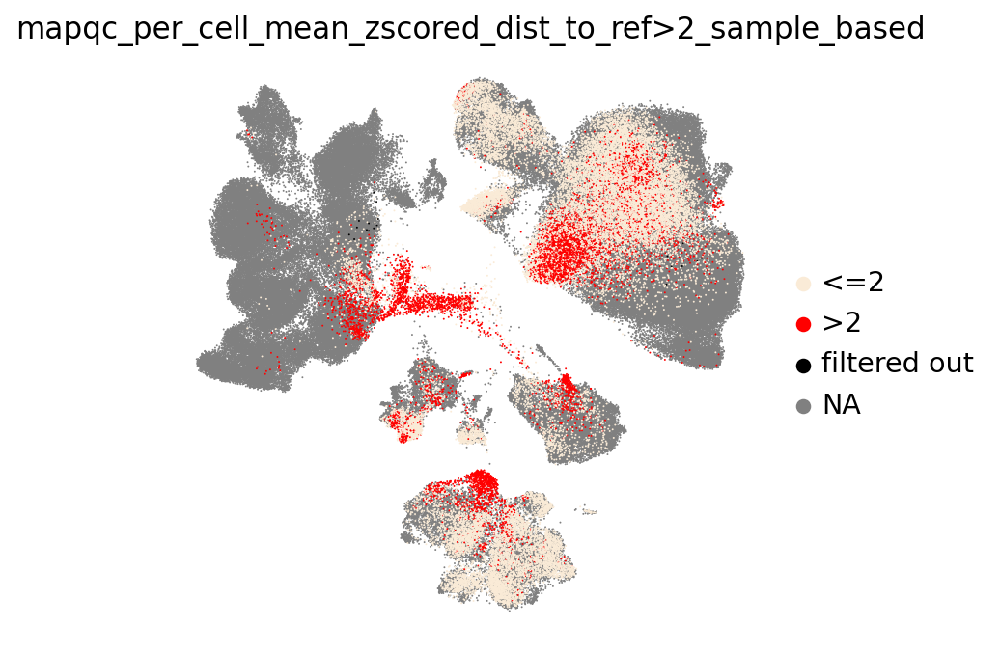

In [15]:
plotting.plot_umap_cell_level_results(results_disease, size=3)

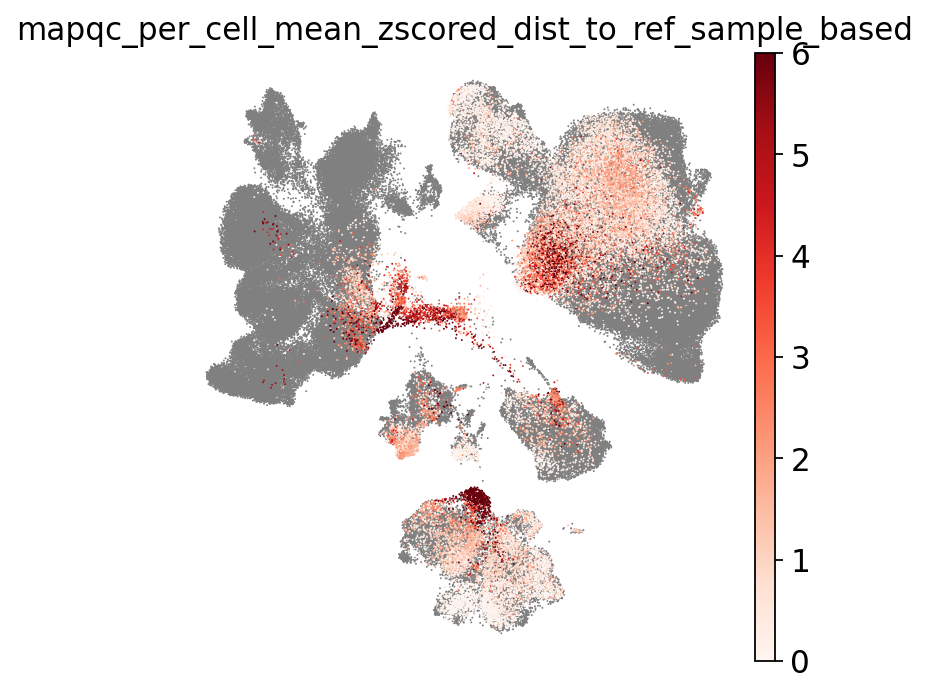

In [233]:
plotting.plot_umap_cell_level_results(
    results_disease, size=3, color_by="zscore", vmin=0, vmax=6
)

### Analyze non-mixing epithelial cells:

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


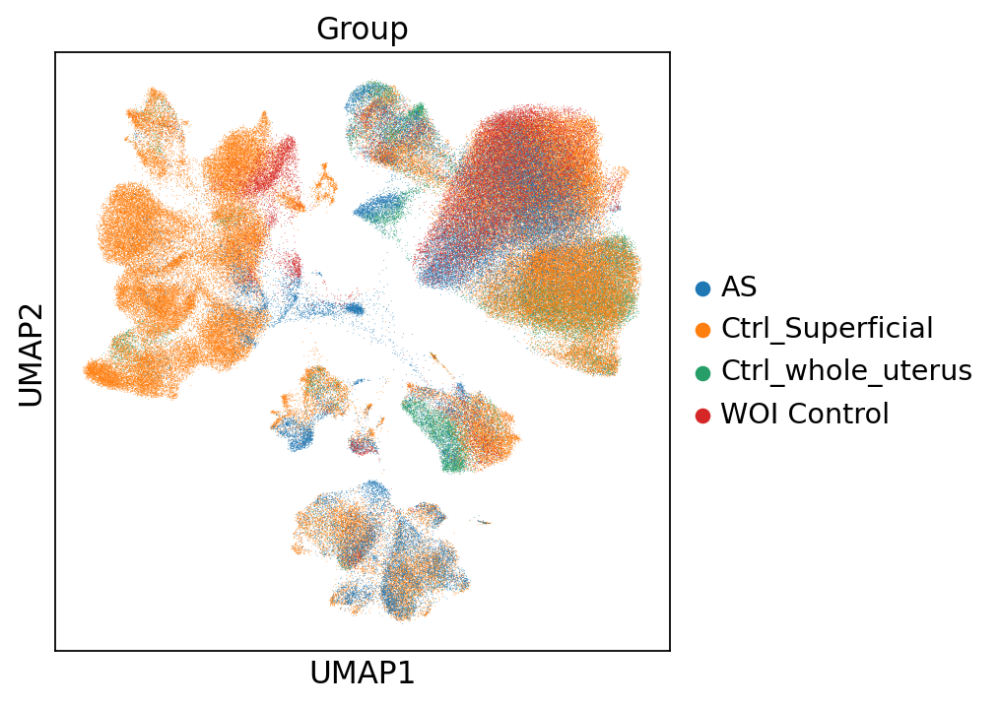

In [16]:
sc.pl.umap(adata_emb, color=["Group"])

In [228]:
adata_emb.obs.loc[adata_emb.obs.ref_or_query == "query", "celltype"] = np.nan

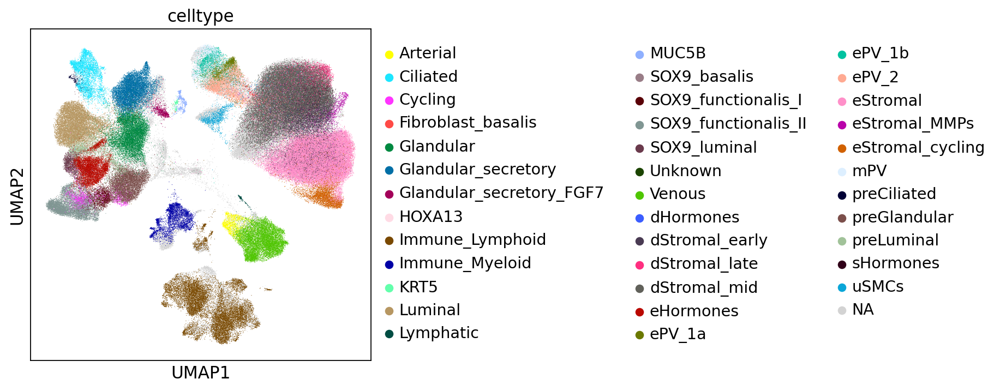

In [229]:
sc.pl.umap(adata_emb, color="celltype", size=1)

add extra category to visualize reference, query healthy, query disease

In [164]:
adata_emb.obs["reference_or_query_subset"] = adata_emb.obs.Group.map(
    {
        "AS": "Query Asherman Syndrome",
        "WOI Control": "Query control",
        "Ctrl_Superficial": "Reference",
        "Ctrl_whole_uterus": "Reference",
    }
)

In [165]:
palette_ref_q = {
    "Reference": "lightgrey",
    "Query control": "dodgerblue",
    "Query Asherman Syndrome": "darkblue",
}

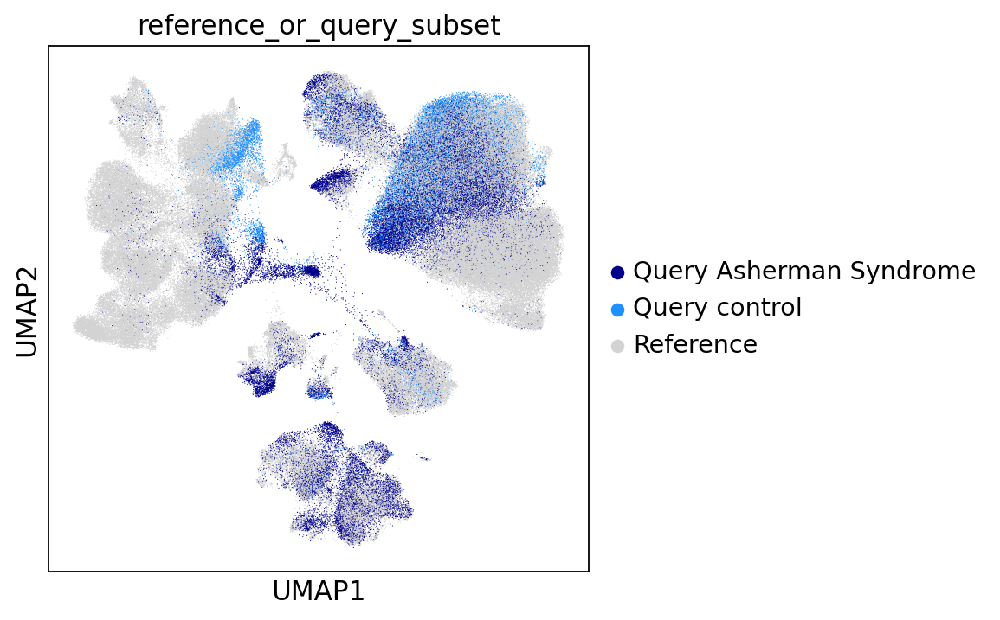

In [178]:
sc.pl.umap(adata_emb, color="reference_or_query_subset", palette=palette_ref_q, size=1)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


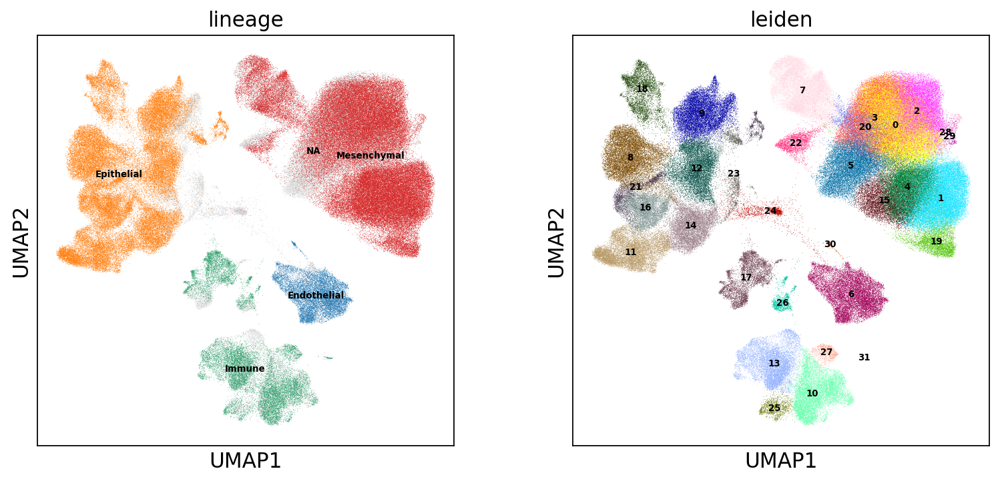

In [17]:
sc.pl.umap(
    adata_emb, color=["lineage", "leiden"], legend_loc="on data", legend_fontsize=6
)

copy celltype annotations from adata_full (has them split by ref versus query):

In [238]:
for cat in ["celltype", "celltype_query"]:
    adata_emb.obs[cat] = adata_full.obs.loc[adata_emb.obs.index, cat]

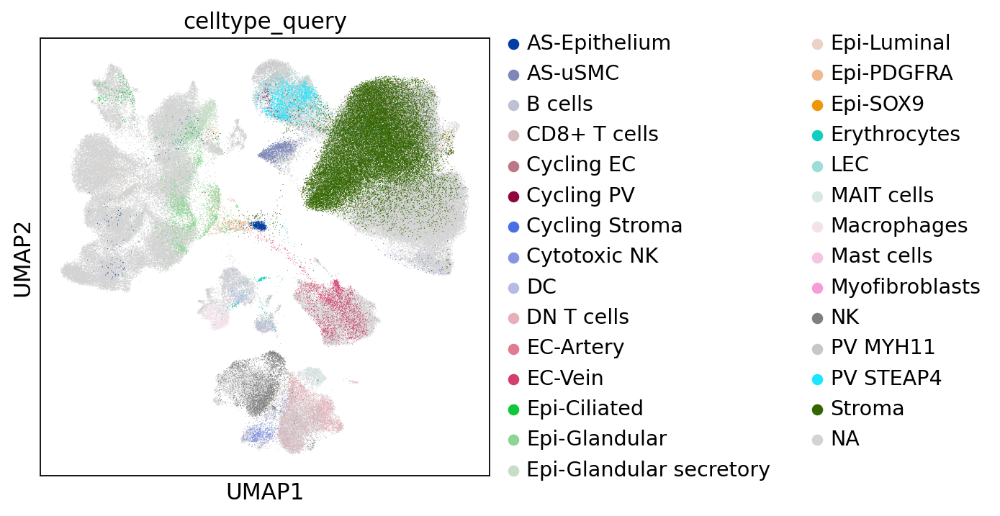

In [244]:
sc.pl.umap(adata_emb, color="celltype_query", size=1)

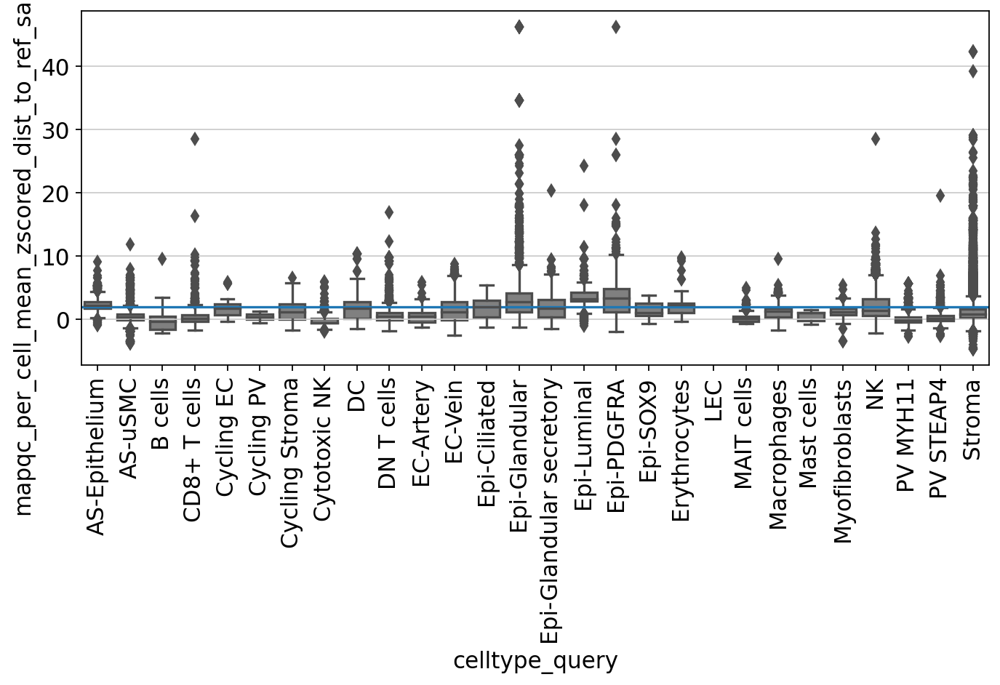

In [242]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    adata_emb.obs,
    x="celltype_query",
    y="mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    color="grey",
    ax=ax,
)
ax.tick_params(axis="x", rotation=90)
plt.axhline(y=2, xmin=0, xmax=20)

In [18]:
epi_clusters = [8, 9, 11, 12, 14, 16, 18, 21, 23, 24]

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


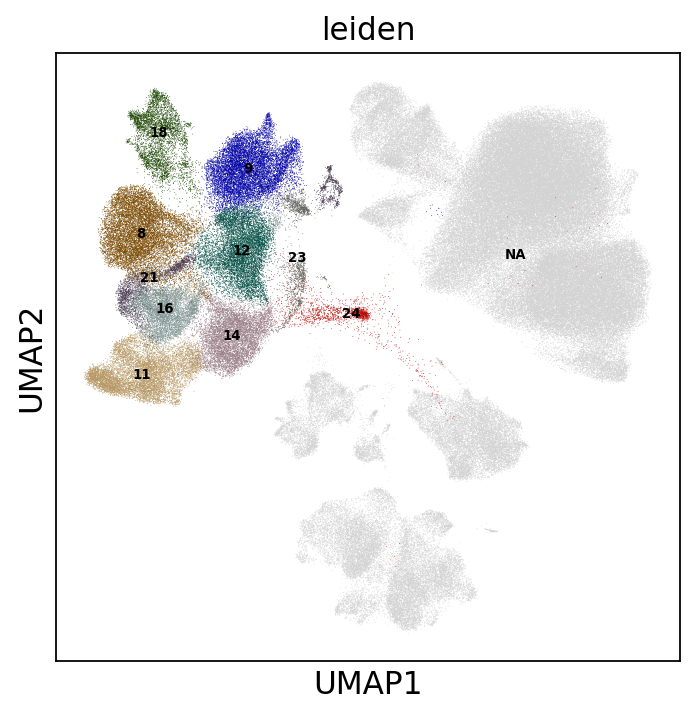

In [19]:
sc.pl.umap(
    adata_emb,
    color=["leiden"],
    groups=epi_clusters,
    legend_loc="on data",
    legend_fontsize=6,
)

subset to big epithelial cluster:

In [20]:
adata_epi_emb = adata_emb[adata_emb.obs.leiden.isin(epi_clusters)]

re-calculate knn graph and umap:

In [21]:
sc.pp.neighbors(adata_epi_emb, n_neighbors=30)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_o

In [22]:
sc.tl.umap(adata_epi_emb)

In [23]:
sc.tl.leiden(adata_epi_emb, key_added="leiden_epi", resolution=1)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/

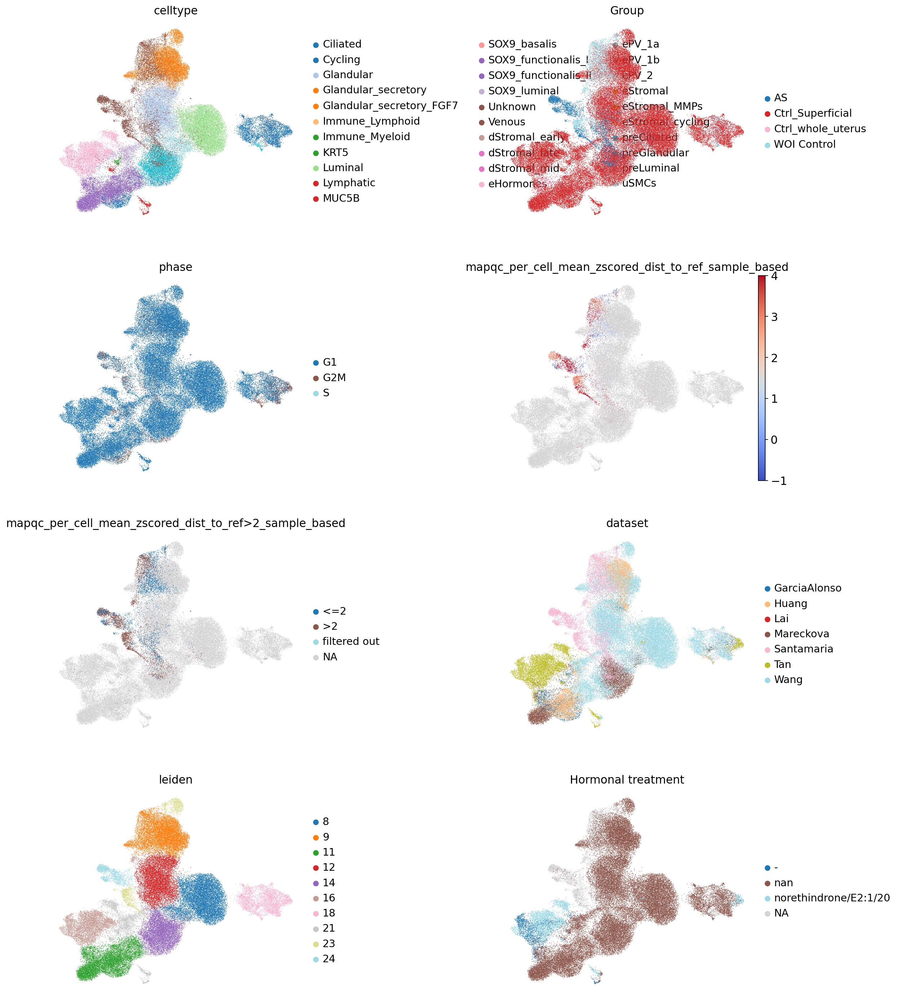

In [26]:
sc.pl.umap(
    adata_epi_emb,
    color=[
        "celltype",
        "Group",
        "phase",
        "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
        "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
        "dataset",
        "leiden",
        "Hormonal treatment",
    ],
    frameon=False,
    wspace=0.6,
    ncols=2,
    vmax=4,
    palette="tab20",
    cmap="coolwarm",
    vmin=-1,
)

#### Analyze counts: create count object of epithelial cells:

In [27]:
adata_epi = adata_full[adata_epi_emb.obs.index, :].to_memory()

In [28]:
adata_epi.obsm["X_umap"] = adata_epi_emb.obsm["X_umap"]
for obs_cat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
    "leiden",
    "leiden_epi",
]:
    adata_epi.obs[obs_cat] = adata_epi_emb.obs.loc[adata_epi.obs.index, obs_cat]

Check marker expression:

"Specifically, we identified two SOX9+ subpopulations: SOX9 functionalis I and II, which we mapped to the functionalis glands (Supplementary Figure 4a). The SOX9 functionalis I population expressed CDH2, high levels of SOX9 and was marked by the expression of PHLDA1 and SLC7A11. The SOX9 functionalis II population exhibited lower expression of SOX9, was negative for CDH2 and distinctly expressed KMO, IHH and EMID1. The luminal proliferative epithelium was defined by the presence of SOX9 luminal (LGR5+), pre-ciliated and ciliated cells (Figure 1f, 2a), as previously described by us15."<br>
"For the preGlandular population these included OPRK1, SUFU, CBR3, HPRT1, and for the preLuminal population SULT1E1 was the most specific marker (Figure 2a). " <br>
"analysing a single sample profiled from the late secretory phase, we observed the presence of a glandular secretory population that upregulated FGF7, a mitogen found to have a role in wound healing in other contexts"<br>
"We detected a previously described population of MUC5B epithelial cells16 expressing MUC5B, TFF3, SAA1, BPIFB1."<br>
<br>
And from other (previous) publication (https://www.nature.com/articles/s41588-021-00972-2):<br>
"(1) SOX9 populations, enriched in the proliferative phase and expressing genes characteristic of rising estrogen levels (MMP7, ESR1); (2) ciliated cells (PIFO, TPPP3); (3) lumenal cells (LGR5); and (4) glandular cells (SCGB2A2)"<br>
and figure 2 from this paper has markers for glandular/glandular secretory that I use below (also other markers that I haven't tried yet)

In [29]:
epithelial_markers = {
    "SOX9_functionalis_I": [
        "SOX9",
        "CDH2",
        "PHLDA1",
        "SLC7A11",
    ],  # SOX9 high in functionalis I, low in functionalis II, CDH2 for SOX9 functionalis I (II negative)
    "SOX9_functionalis_II": ["KMO", "IHH", "EMID1"],
    "SOX9_luminal": ["LGR5"],  # I think also luminal in general
    "preLuminal": ["SULT1E1"],
    "MUC5B": ["MUC5B", "TFF3", "SAA1", "BPIFB1"],  # MUC5B epithelial
    "preGlandular": ["OPRK1", "SUFU", "CBR3", "HPRT1"],  # preGlandular
    "Glandular_secretory_FGF7": ["FGF7"],
    "Glandular": ["SCGB2A2"],  # glandular cells, also but lower in glandular secretory
    "Glandular_secretory": [
        "DPP4",
        "GPX3",
        "PAEP",
    ],  # GPX3 and PAEP also but lower in glandular
}

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


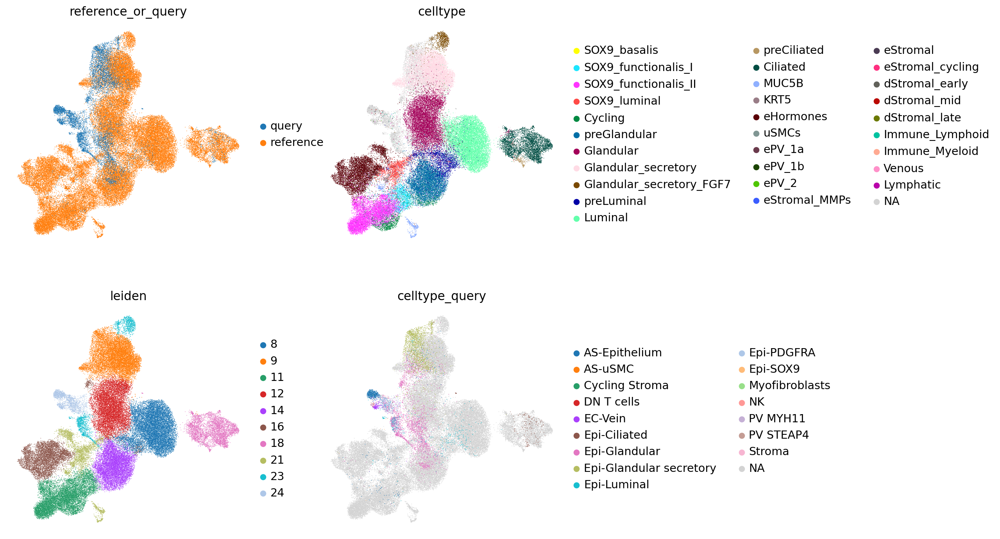

SOX9_functionalis_I:


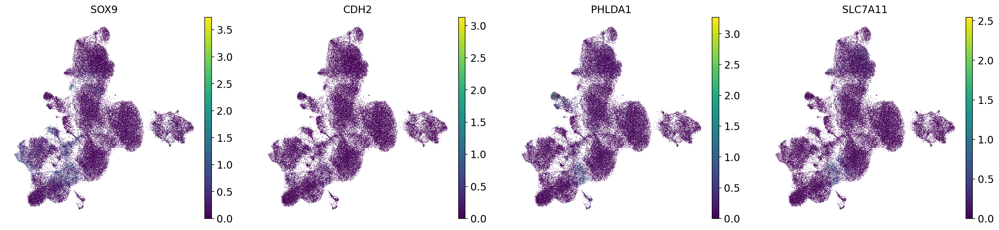

SOX9_functionalis_II:


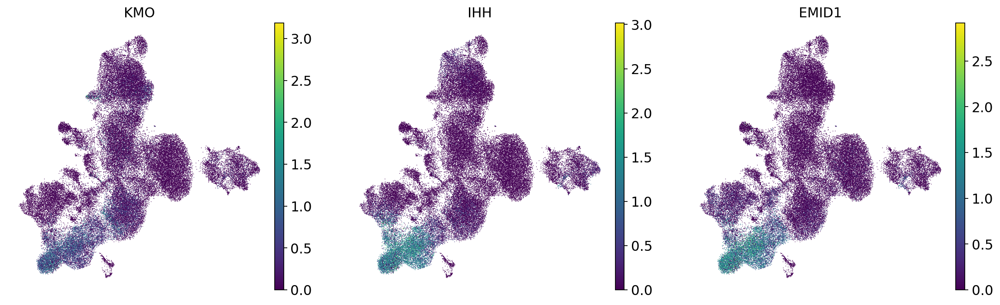

SOX9_luminal:


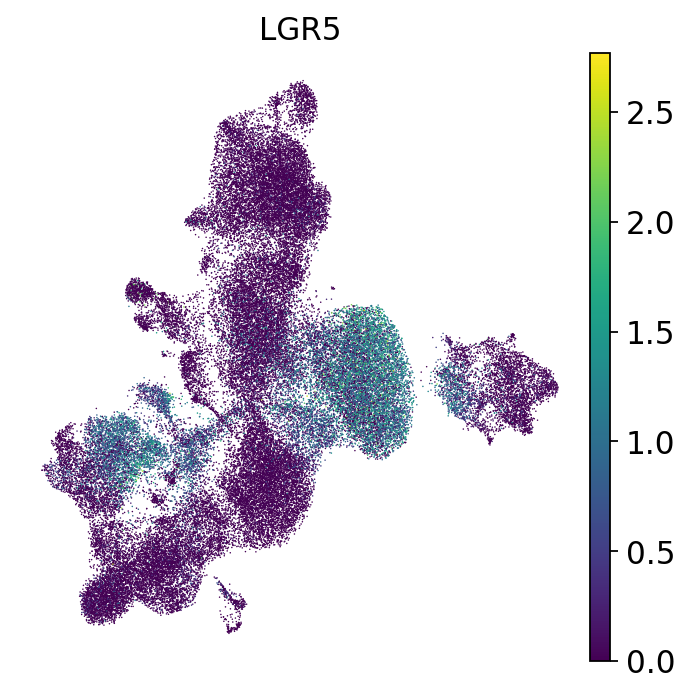

preLuminal:


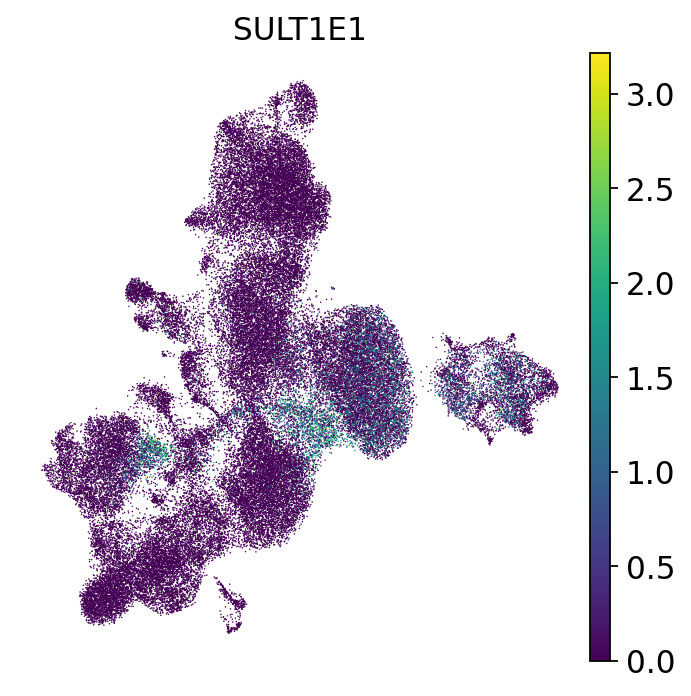

MUC5B:


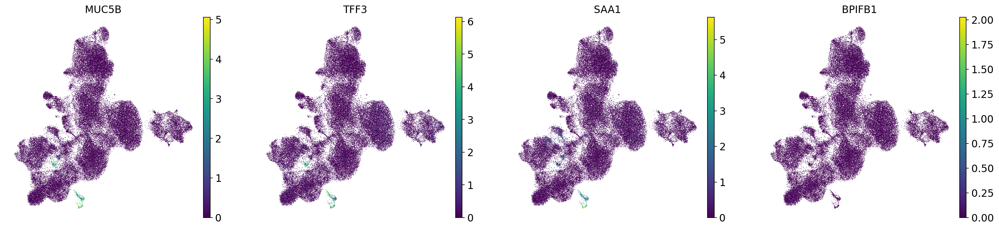

preGlandular:


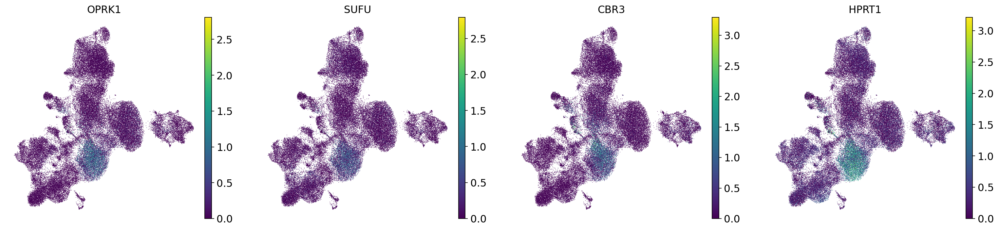

Glandular_secretory_FGF7:


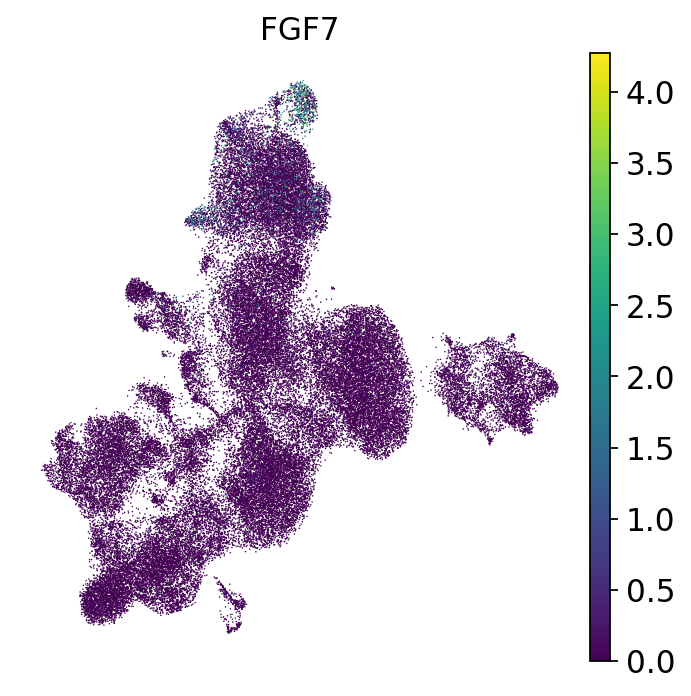

Glandular:


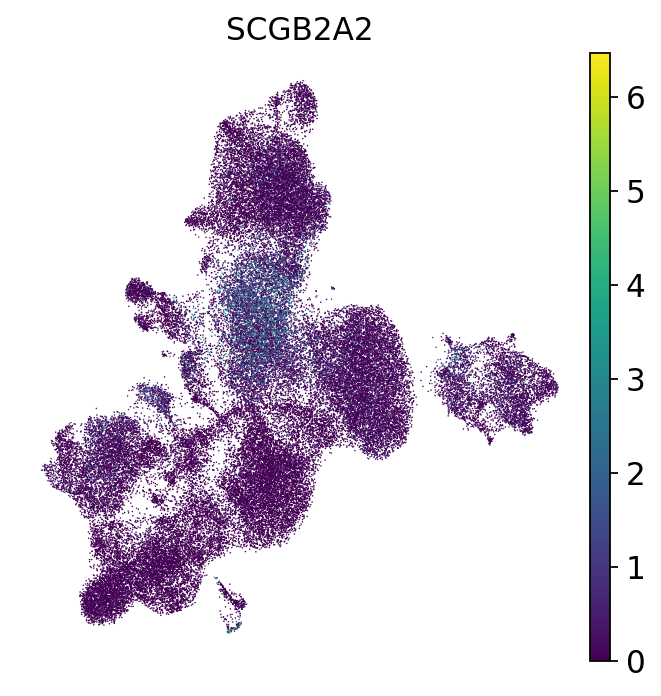

Glandular_secretory:


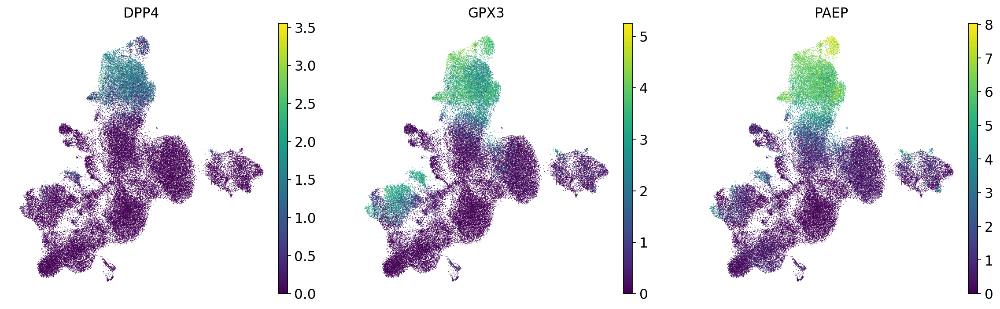

In [30]:
sc.pl.umap(
    adata_epi,
    color=["reference_or_query", "celltype", "leiden", "celltype_query"],
    frameon=False,
    ncols=2,
)
for ct, markers in epithelial_markers.items():
    print(f"{ct}:")
    sc.pl.umap(adata_epi, color=markers, ncols=4, frameon=False, sort_order=False)

In [31]:
adata_epi.obs["celltype_or_query_leiden"] = adata_epi.obs.celltype.tolist()
adata_epi.obs.loc[
    adata_epi.obs.reference_or_query == "query", "celltype_or_query_leiden"
] = [
    f"{cl} (query)"
    for cl in adata_epi.obs.loc[adata_epi.obs.reference_or_query == "query", "leiden"]
]
celltype_or_cluster_counts = adata_epi.obs.celltype_or_query_leiden.value_counts()
celltype_or_cluster_mapping = {
    ct_or_cluster: (
        ct_or_cluster if celltype_or_cluster_counts[ct_or_cluster] > 50 else "Other"
    )
    for ct_or_cluster in celltype_or_cluster_counts.index
}
adata_epi.obs.celltype_or_query_leiden = adata_epi.obs.celltype_or_query_leiden.map(
    celltype_or_cluster_mapping
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


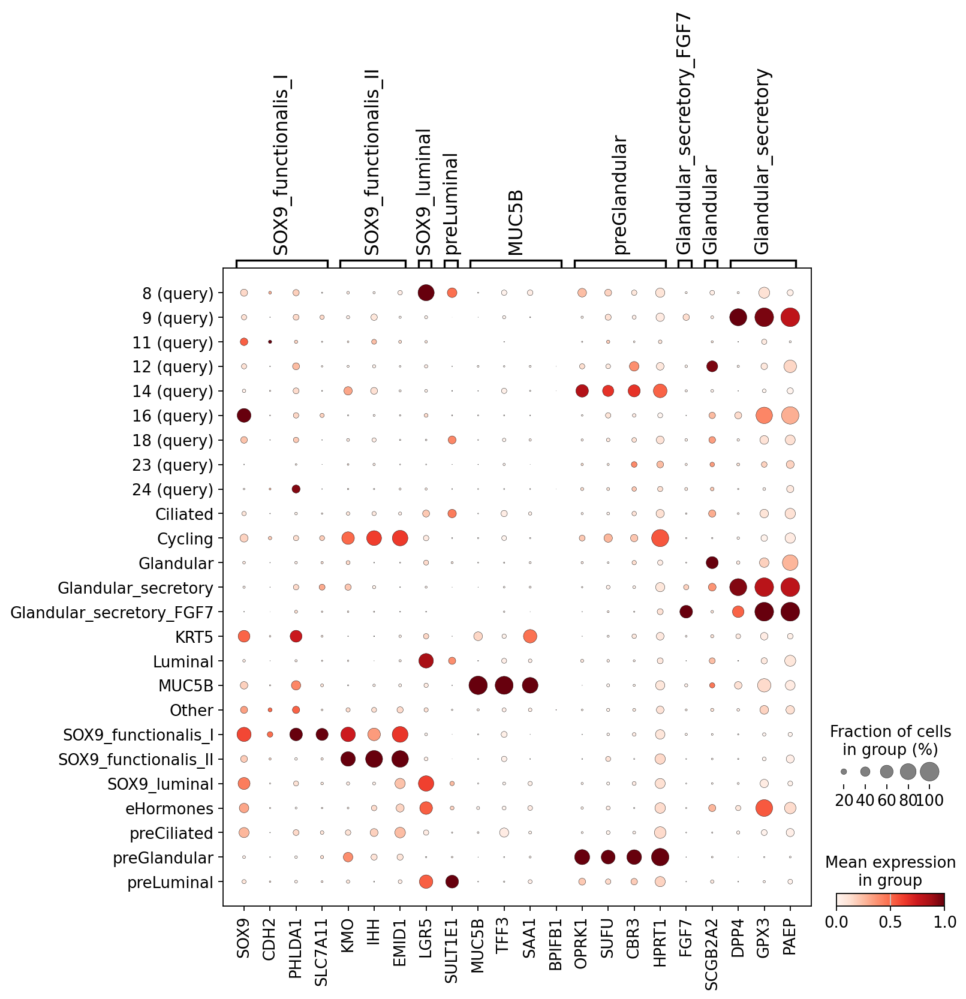

In [32]:
sc.pl.dotplot(
    adata_epi,
    groupby="celltype_or_query_leiden",
    var_names=epithelial_markers,
    standard_scale="var",
)

In [33]:
pd.crosstab(
    adata_epi_emb.obs.Group,
    adata_epi_emb.obs["mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based"],
)

mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based,<=2,>2,filtered out
Group,,,
AS,1117,2042,13
WOI Control,1565,1711,0


In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

In [35]:
epi_ct_counts = adata_epi.obs.celltype_query.value_counts()
cts_to_plot = epi_ct_counts.loc[epi_ct_counts > 50].index

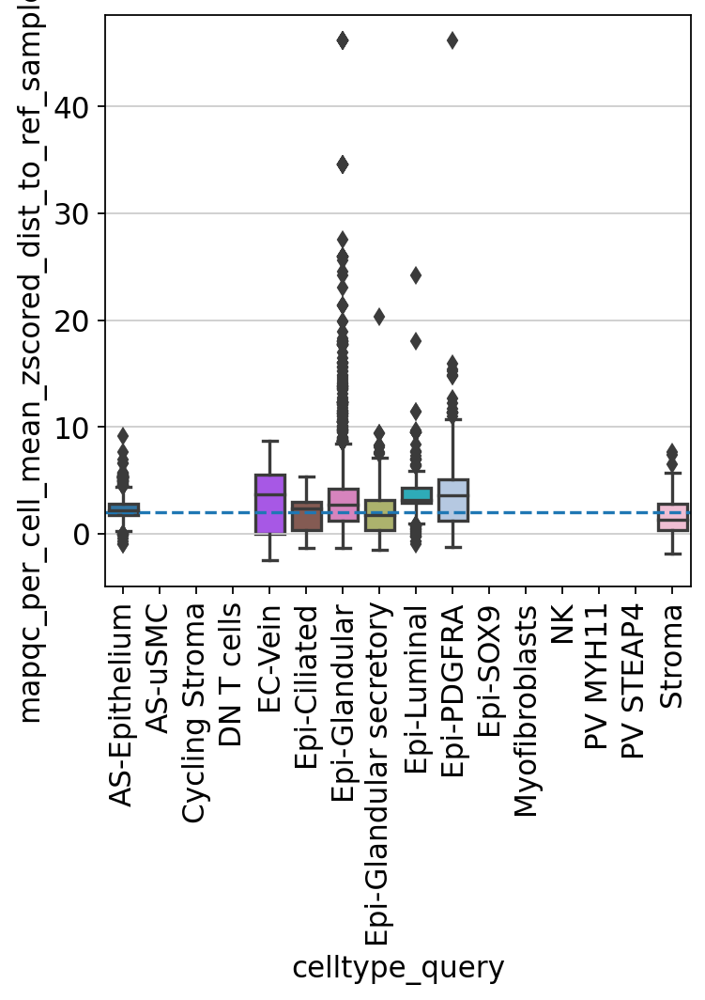

In [36]:
fig, ax = plt.subplots()
sns.boxplot(
    adata_epi.obs.loc[adata_epi.obs.celltype_query.isin(cts_to_plot), :],
    x="celltype_query",
    y="mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    ax=ax,
)
plt.axhline(y=2, xmin=0, xmax=10, linestyle="--")
ax.tick_params(axis="x", rotation=90)

either subcluster such that distant cells fall mostly in a separate subcluster, or do a DEA based on mixing score: 

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


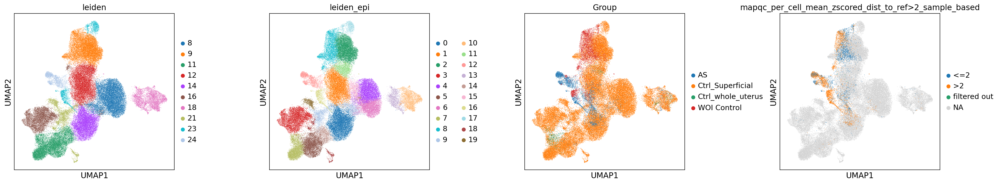

In [37]:
sc.pl.umap(
    adata_epi,
    color=[
        "leiden",
        "leiden_epi",
        "Group",
        "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
    ],
    wspace=0.45,
)

In [38]:
query_count_per_cluster = adata_epi.obs.loc[
    adata_epi.obs.reference_or_query == "query", "leiden_epi"
].value_counts()
clusters_with_suff_query = query_count_per_cluster.loc[
    query_count_per_cluster > 100
].index

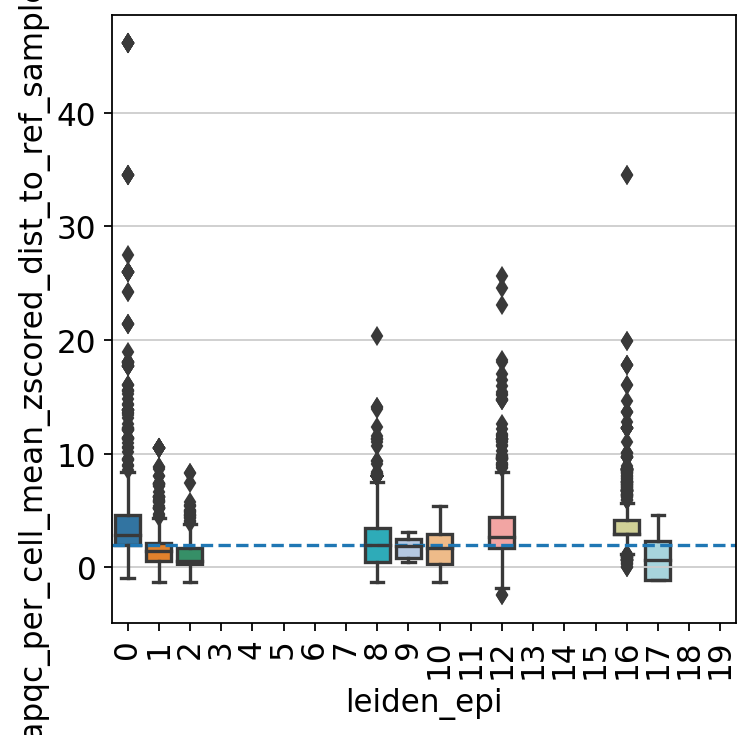

In [39]:
fig, ax = plt.subplots()
sns.boxplot(
    adata_epi.obs.loc[adata_epi.obs.leiden_epi.isin(clusters_with_suff_query), :],
    x="leiden_epi",
    y="mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    ax=ax,
)
ax.tick_params(axis="x", rotation=90)
plt.axhline(y=2, xmin=0, xmax=19, linestyle="--")
plt.show()

In [40]:
adata_epi.uns["log1p"]["base"] = None

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


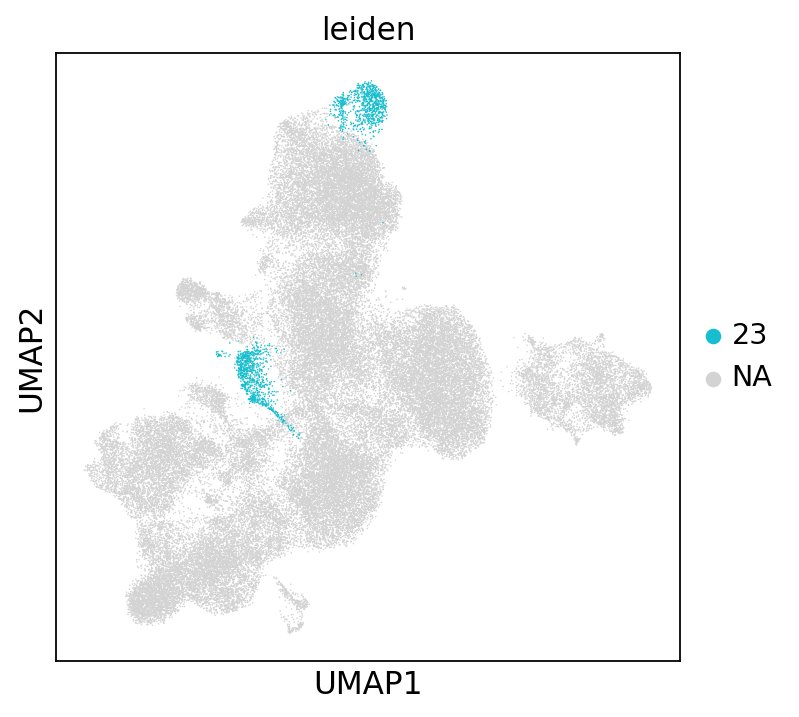

In [80]:
sc.pl.umap(adata_epi, color="leiden", groups=[23])

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


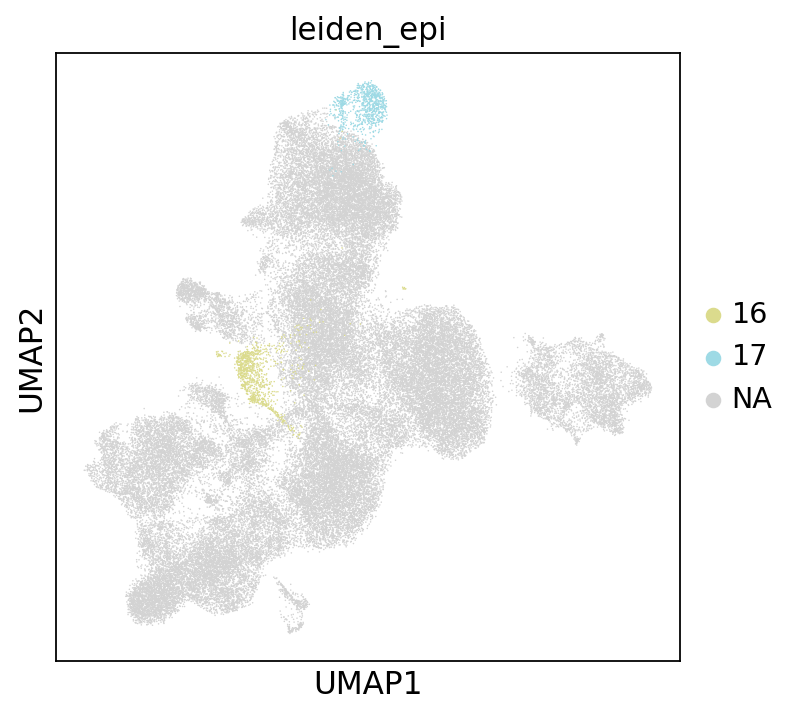

In [78]:
sc.pl.umap(adata_epi, color="leiden_epi", groups=["16", "17"])

In [92]:
# sc.tl.rank_genes_groups(adata_epi, groupby="leiden_epi", groups=["16"], reference="17")

In [93]:
# sc.pl.rank_genes_groups(adata_epi)

In [96]:
# sc.pl.umap(adata_epi, color=["PDGFRA"])

In [41]:
sc.tl.rank_genes_groups(adata_epi, groupby="leiden_epi", groups=[12, 16])

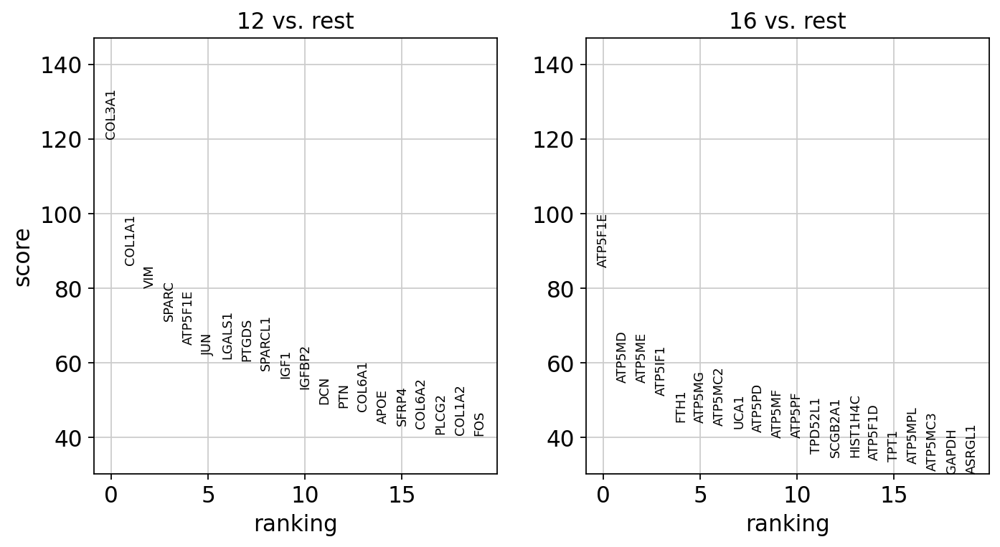

In [42]:
sc.pl.rank_genes_groups(adata_epi)

In [43]:
cluster_16_markers_used_during_mapping = [
    gene
    for gene in sc.get.rank_genes_groups_df(adata_epi, group="16").names[:100]
    if adata_full.var.loc[gene, "highly_variable"]
]

In [44]:
cluster_16_neg_markers_used_during_mapping = [
    gene
    for gene in sc.get.rank_genes_groups_df(adata_epi, group="16").names[-100:]
    if adata_full.var.loc[gene, "highly_variable"]
]

In [45]:
cluster_16_markers = [
    "ATP5F1E",
    "ATP5MD",
    "ATP5ME",
    "ATP5IF1",
    "FTH1",
    "UCA1",
    "TPD52L1",
    "SCGB2A1",
    "HIST1H4C",
]

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


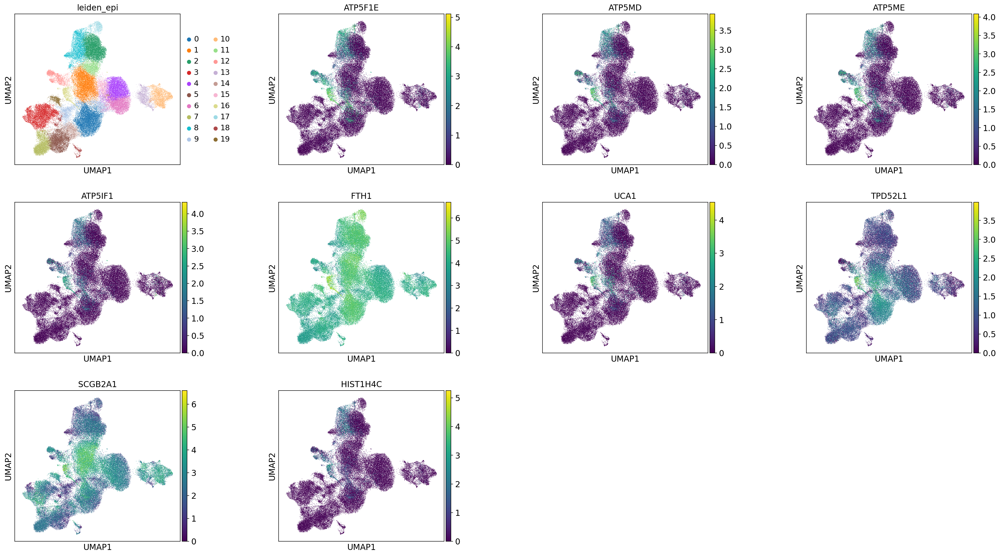

In [46]:
sc.pl.umap(adata_epi, color=["leiden_epi"] + cluster_16_markers, wspace=0.45)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


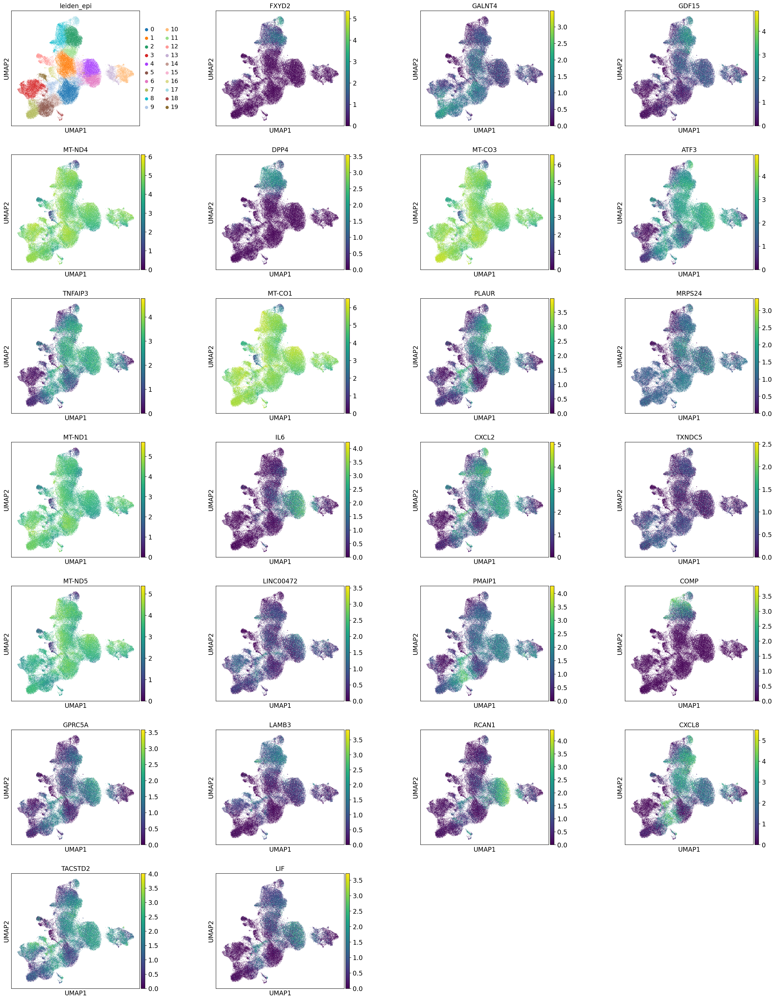

In [99]:
sc.pl.umap(
    adata_epi,
    color=["leiden_epi"] + cluster_16_neg_markers_used_during_mapping[-25:],
    wspace=0.45,
)

In [48]:
cluster_12_markers = ["COL3A1", "COL1A1", "SPARC", "LGALS1", "PTGDS"]

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


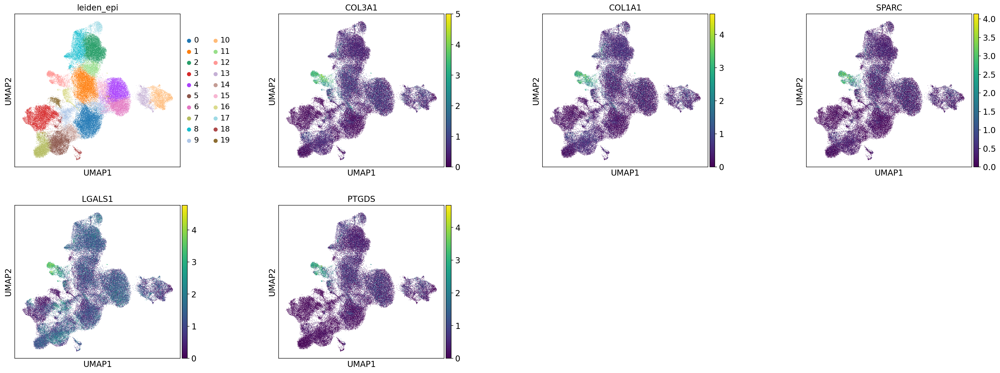

In [49]:
sc.pl.umap(adata_epi, color=["leiden_epi"] + cluster_12_markers, wspace=0.45)

from figure 1c AS paper:

In [50]:
paper_markers_AS_epi = ["SLPI", "HSPA1A", "SOCS3", "SNHG9", "MMP7"]

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


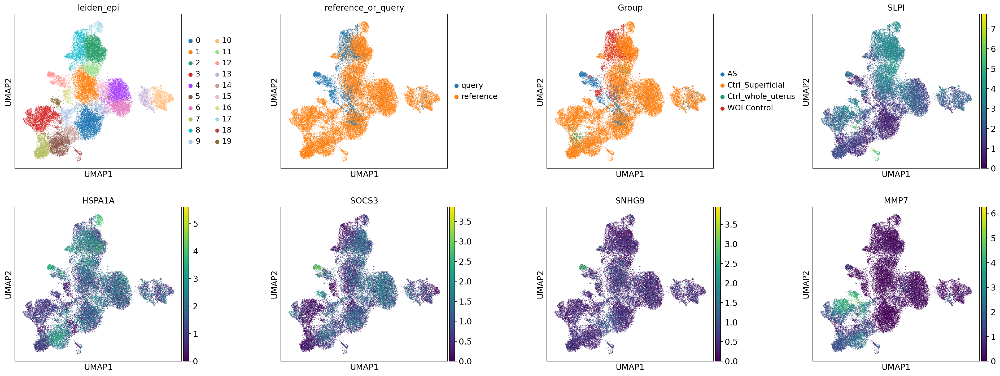

In [51]:
sc.pl.umap(
    adata_epi,
    color=["leiden_epi", "reference_or_query", "Group"] + paper_markers_AS_epi,
    wspace=0.45,
)

In [56]:
adata_epi.obs["ref_or_query_condition"] = adata_epi.obs.reference_or_query.tolist()
adata_epi.obs.loc[
    adata_epi.obs.Group == "AS", "ref_or_query_condition"
] = "query_disease"
adata_epi.obs.loc[
    adata_epi.obs.Group == "WOI Control", "ref_or_query_condition"
] = "query_control"
adata_epi.obs["leiden_epi_source"] = [
    f"{cl} ({cond})"
    for cl, cond in zip(adata_epi.obs.leiden_epi, adata_epi.obs.ref_or_query_condition)
]
# clean up to remove groups that have fewer than min_n_cells:
leiden_epi_source_counts = adata_epi.obs.leiden_epi_source.value_counts()
leiden_epi_source_mapping = {
    group: (group if leiden_epi_source_counts[group] > 50 else "Other")
    for group in leiden_epi_source_counts.index
}
adata_epi.obs.leiden_epi_source = adata_epi.obs.leiden_epi_source.map(
    leiden_epi_source_mapping
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


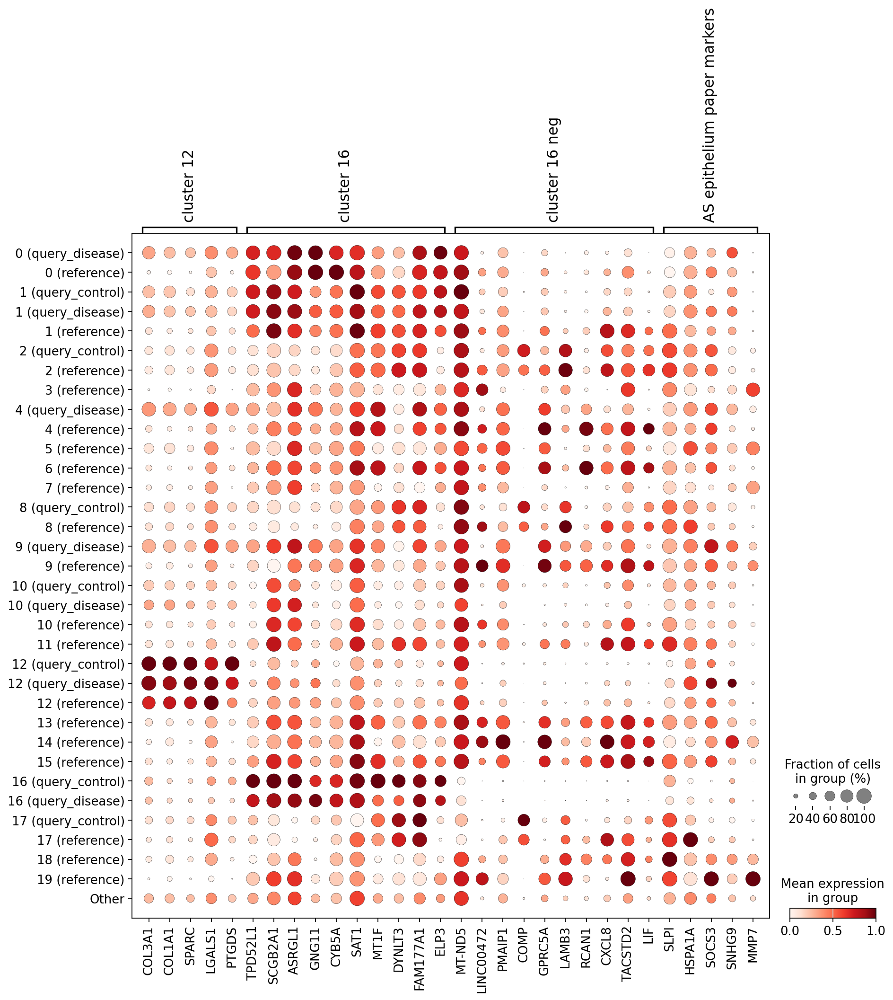

In [57]:
sc.pl.dotplot(
    adata_epi,
    var_names={
        "cluster 12": cluster_12_markers,
        "cluster 16": cluster_16_markers_used_during_mapping[:10],
        "cluster 16 neg": cluster_16_neg_markers_used_during_mapping[-10:],
        "AS epithelium paper markers": paper_markers_AS_epi,
    },
    groupby="leiden_epi_source",
    standard_scale="var",
)

Notes:
- cluster 12 (seemingly disease specific cluster) has genes (COL3A1, COL1A1, SPARC) that are also expressed in query control cells from that same cluster. Question to answer: does that mean these are not disease-specific cells, but rather batch-related artefacts?
- cluster 16: query-specific genes again, this cluster does not include (>100) reference cells. check if these were used during mapping? Seems batch-effect related. This would mean that mapQC correctly flags these cells as not well mapped based on the control.

In [58]:
adata_full.obsm["X_umap"] = adata_emb[adata_full.obs.index, :].obsm["X_umap"]

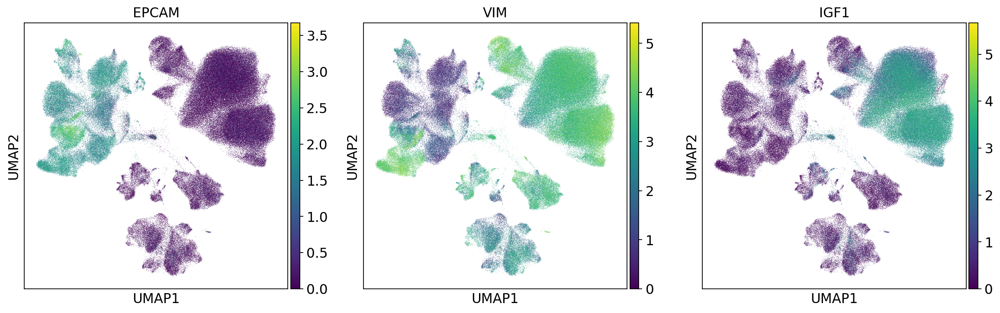

In [59]:
sc.pl.umap(adata_full, color=["EPCAM", "VIM", "IGF1"])

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


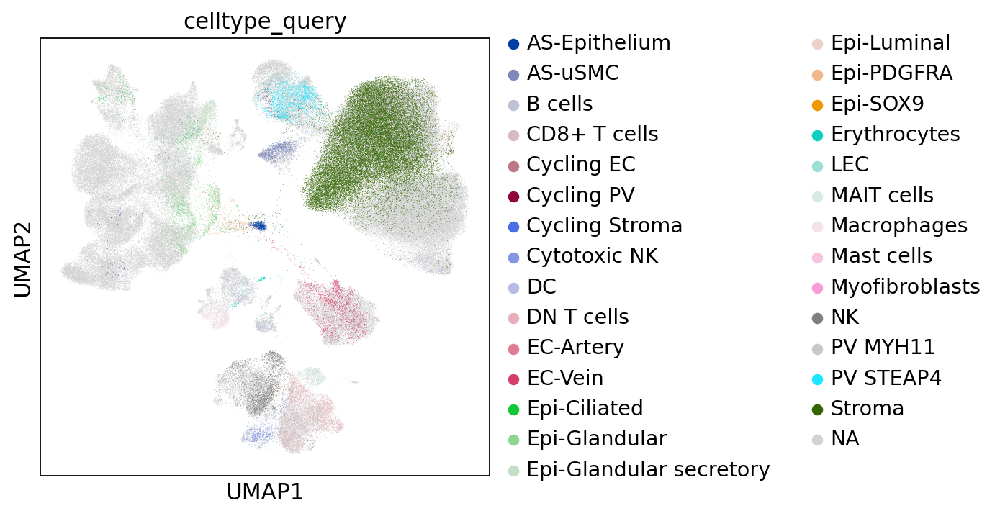

In [60]:
sc.pl.umap(adata_full, color="celltype_query")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


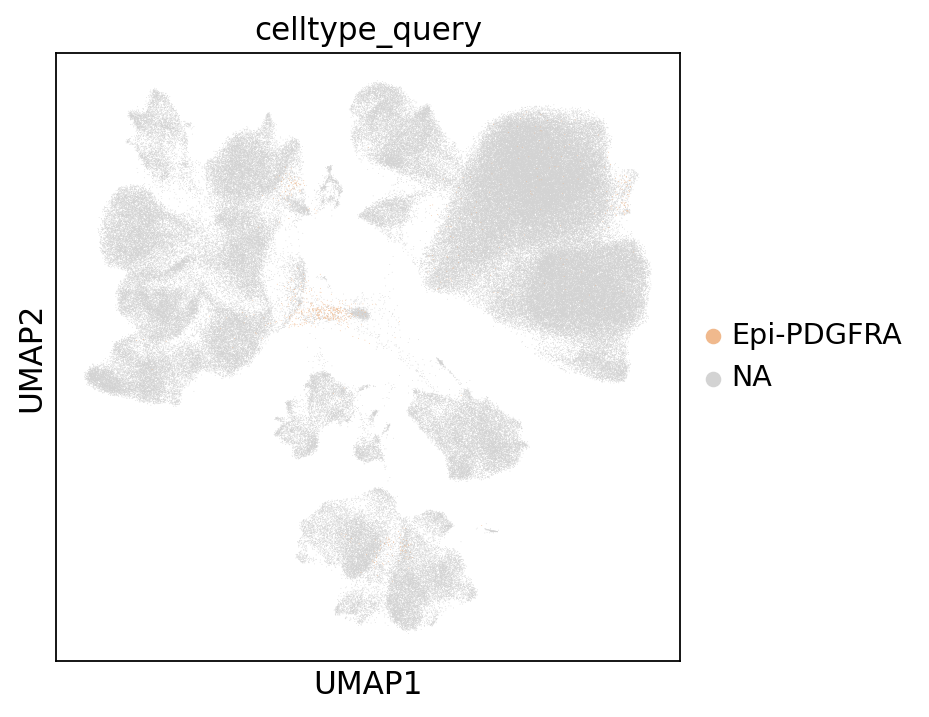

In [75]:
sc.pl.umap(adata_full, color="celltype_query", groups=["Epi-PDGFRA"])

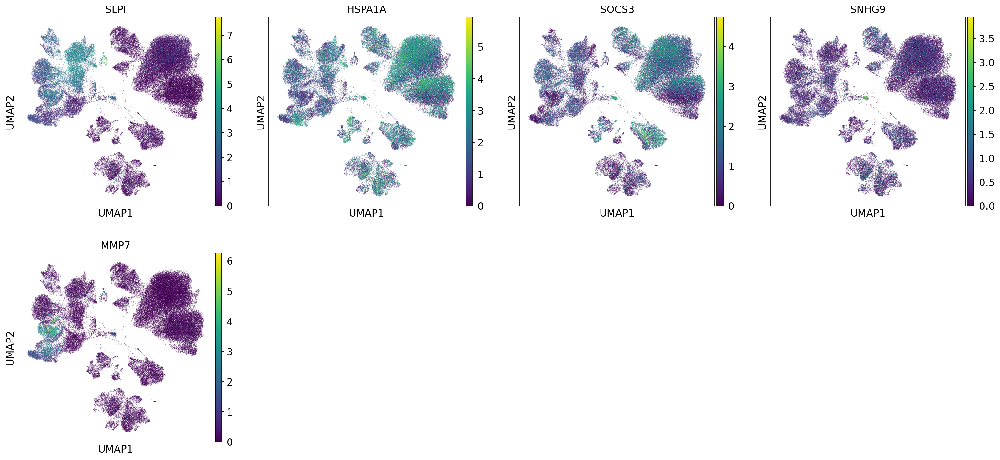

In [264]:
sc.pl.umap(adata_full, color=paper_markers_AS_epi)

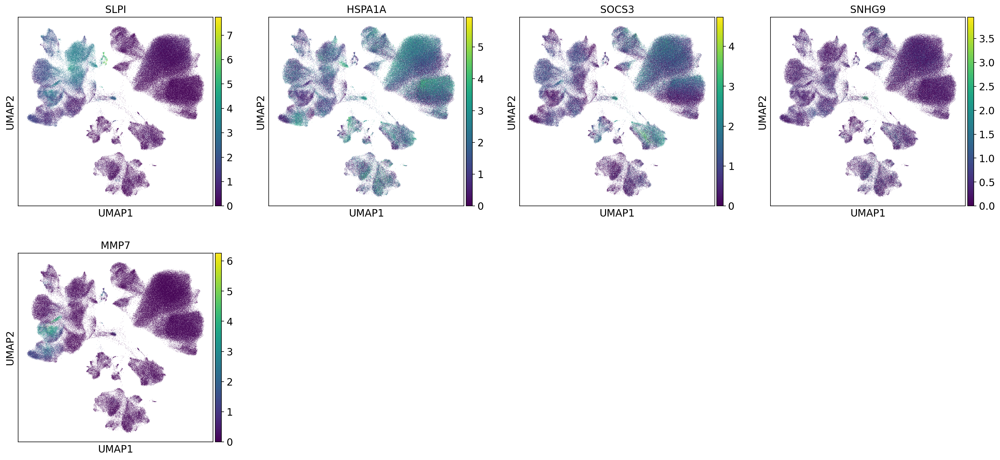

In [62]:
sc.pl.umap(adata_full, color=paper_markers_AS_epi, sort_order=False)

In [63]:
adata_full.obs["leiden"] = adata_emb.obs.loc[adata_full.obs.index, "leiden"]

In [64]:
adata_full.uns["log1p"]["base"] = None

In [65]:
adata_full.obs.leiden[0] == 7

True

In [66]:
adata_full = adata_full.to_memory()

In [67]:
sc.tl.rank_genes_groups(adata_full, groupby="leiden", reference=0)  # also try 22

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:394: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, 'names'] = self.var_names[global_indices]
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:396: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, 'scores'] = scores[global_indices]
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/tool

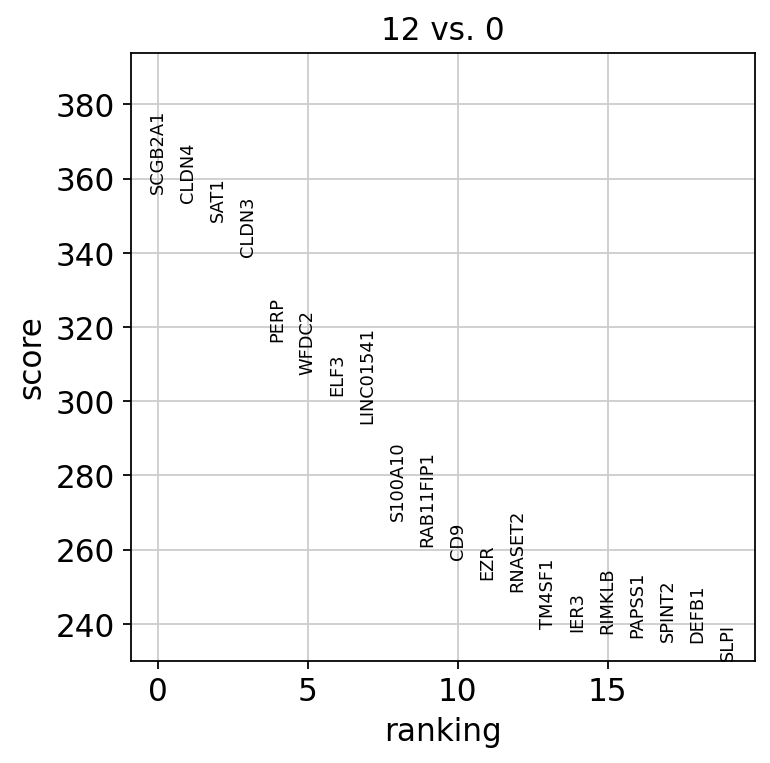

In [68]:
sc.pl.rank_genes_groups(adata_full, groups=["12"])

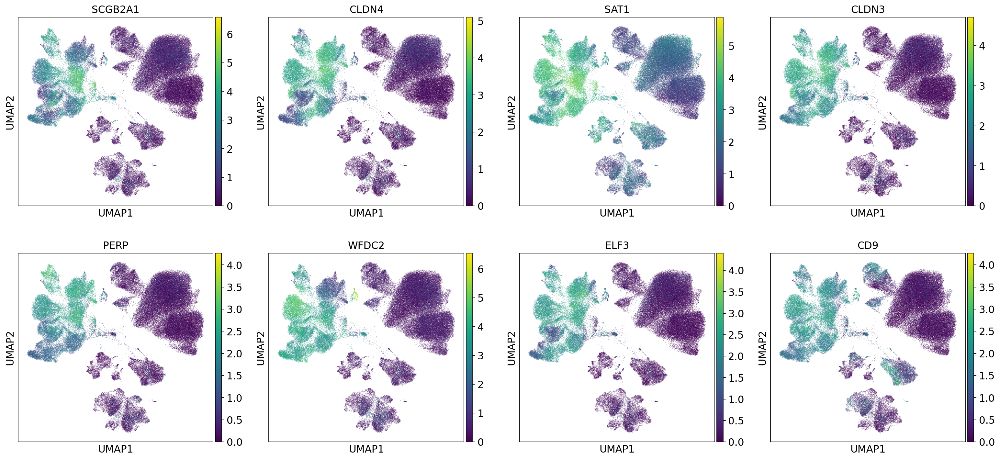

In [69]:
sc.pl.umap(
    adata_full,
    color=["SCGB2A1", "CLDN4", "SAT1", "CLDN3", "PERP", "WFDC2", "ELF3", "CD9"],
)

looks like cluster 12 are doublets right? 

In [245]:
cluster_12_markers

['COL3A1', 'COL1A1', 'SPARC', 'LGALS1', 'PTGDS']

In [246]:
paper_markers_AS_epi

['SLPI', 'HSPA1A', 'SOCS3', 'SNHG9', 'MMP7']

In [266]:
doublet_markers = {
    "epithelial": ["SCGB2A1", "CLDN3", "WFDC2", "ELF3", "CD9"],
    "stromal": ["COL3A1", "COL1A1", "SPARC", "PTGDS"],
    "AS epithelium markers": paper_markers_AS_epi,
}

In [262]:
adata_full.obs["leiden_AS_epithelium"] = adata_full.obs.leiden.tolist()
adata_full.obs.loc[
    (
        (adata_full.obs.celltype_query == "AS-Epithelium")
        & (adata_full.obs.leiden == 24)
    ),
    "leiden_AS_epithelium",
] = "24 (AS Epithelium)"

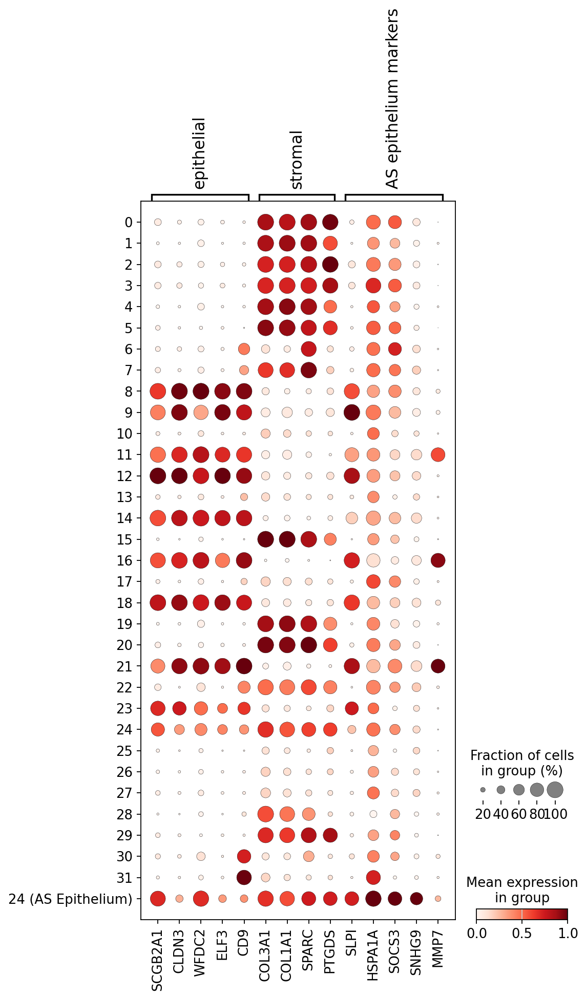

In [268]:
sc.pl.dotplot(
    adata_full,
    groupby="leiden_AS_epithelium",
    var_names=doublet_markers,
    standard_scale="var",
)

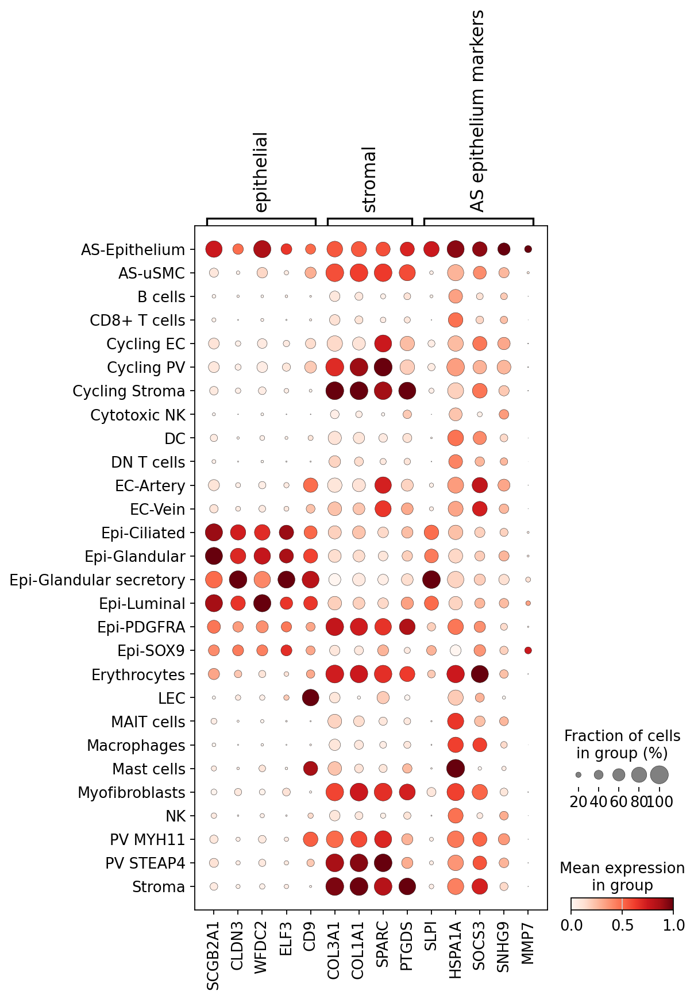

In [269]:
sc.pl.dotplot(
    adata_full,
    groupby="celltype_query",
    var_names=doublet_markers,
    standard_scale="var",
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


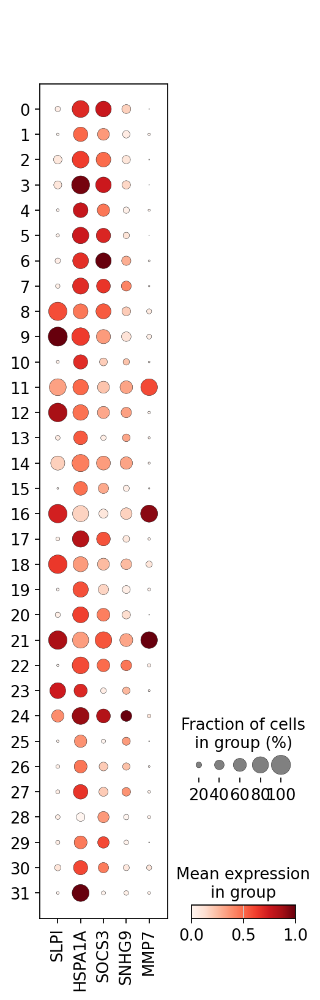

In [72]:
sc.pl.dotplot(
    adata_full, groupby="leiden", var_names=paper_markers_AS_epi, standard_scale="var"
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


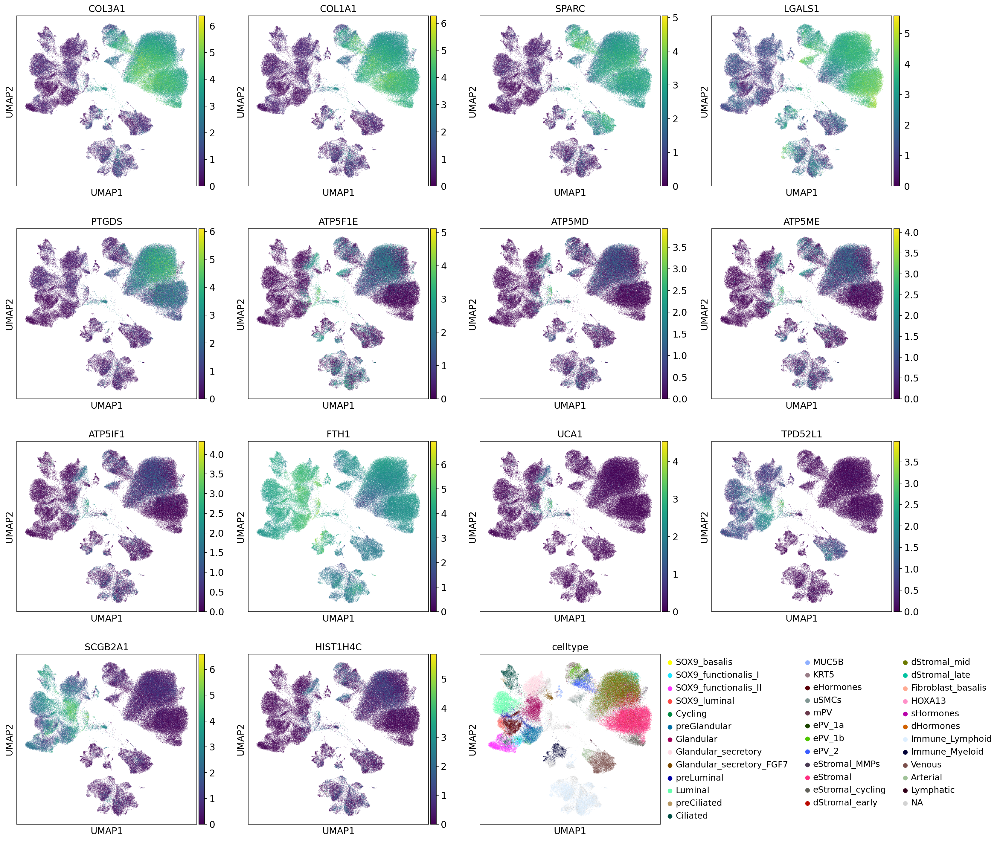

In [73]:
sc.pl.umap(adata_full, color=cluster_12_markers + cluster_16_markers + ["celltype"])

### Analyze non-mixing stromal cells:

make sure that healthy non-mixing don't display the same pattern!

In [179]:
adata_EC_emb.obs["reference_or_query_subset"] = adata_emb.obs.loc[
    adata_EC_emb.obs.index, "reference_or_query_subset"
]

In [105]:
adata_EC_emb = adata_emb[adata_emb.obs.leiden == 6, :].copy()

add mapqc results from both healthy and diseased:

In [112]:
# for stat in [
#     "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
#     "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
# ]:
#     adata_EC_emb.obs[stat] = np.nan
#     healthy_idc = [
#         idx for idx in adata_EC_emb.obs.index if idx in results_healthy.adata.obs.index
#     ]
#     adata_EC_emb.obs.loc[healthy_idc, stat] = results_healthy.adata.obs.loc[
#         healthy_idc, stat
#     ]
#     disease_idc = [
#         idx for idx in adata_EC_emb.obs.index if idx in results_disease.adata.obs.index
#     ]
#     adata_EC_emb.obs.loc[disease_idc, stat] = results_disease.adata.obs.loc[
#         disease_idc, stat
#     ]

In [107]:
sc.pp.neighbors(adata_EC_emb, n_neighbors=30)

In [108]:
sc.tl.umap(adata_EC_emb)

In [191]:
sc.tl.leiden(adata_EC_emb, resolution=0.4, key_added="leiden_EC")

create some further joint metadata:

In [192]:
adata_EC_emb.obs["leiden_EC_group"] = [
    f"{cl} ({gr})" for cl, gr in zip(adata_EC_emb.obs.leiden_EC, adata_EC_emb.obs.Group)
]
adata_EC_emb.obs["leiden_EC_group_sample"] = [
    f"{cl_gr} ({s})"
    for cl_gr, s in zip(adata_EC_emb.obs.leiden_EC_group, adata_EC_emb.obs["sample"])
]

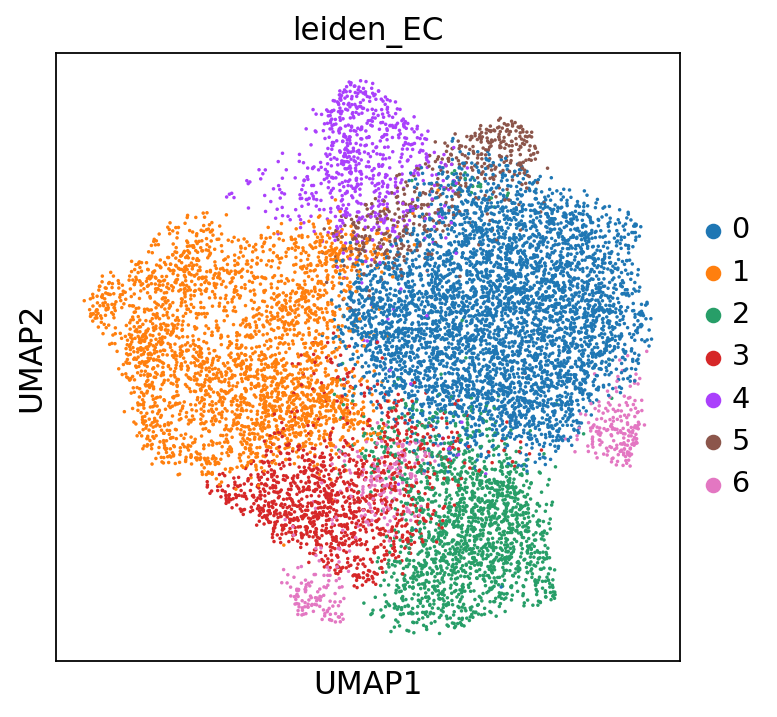

In [193]:
sc.pl.umap(adata_EC_emb, color="leiden_EC")

In [109]:
adata_EC = adata_full[adata_EC_emb.obs.index, :].to_memory()

In [194]:
adata_EC.obsm["X_umap"] = adata_EC_emb.obsm["X_umap"]
for obs_cat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
    "leiden",
    "leiden_EC",
    "leiden_EC_group",
    "leiden_EC_group_sample",
    "reference_or_query_subset",
]:
    adata_EC.obs[obs_cat] = adata_EC_emb.obs.loc[adata_EC.obs.index, obs_cat]

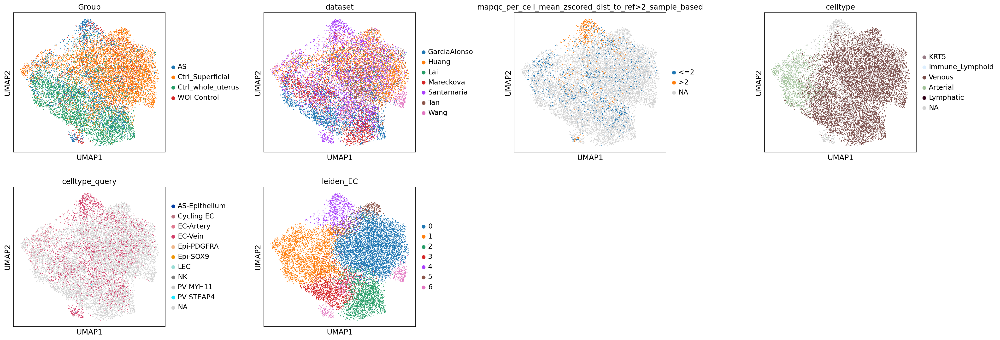

In [196]:
sc.pl.umap(
    adata_EC,
    color=[
        "Group",
        "dataset",
        "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
        "celltype",
        "celltype_query",
        "leiden_EC",
    ],
    wspace=0.5,
)

In [197]:
sc.tl.rank_genes_groups(adata_EC, groupby="leiden_EC")

subset to genes used during mapping:

In [201]:
deg_non_mixing_EC_cl = sc.get.rank_genes_groups_df(adata_EC, group="4")
deg_non_mixing_EC_cl_genes_used_for_mapping = [
    gene
    for gene in deg_non_mixing_EC_cl.names
    if adata_full.var.loc[gene, "highly_variable"]
]

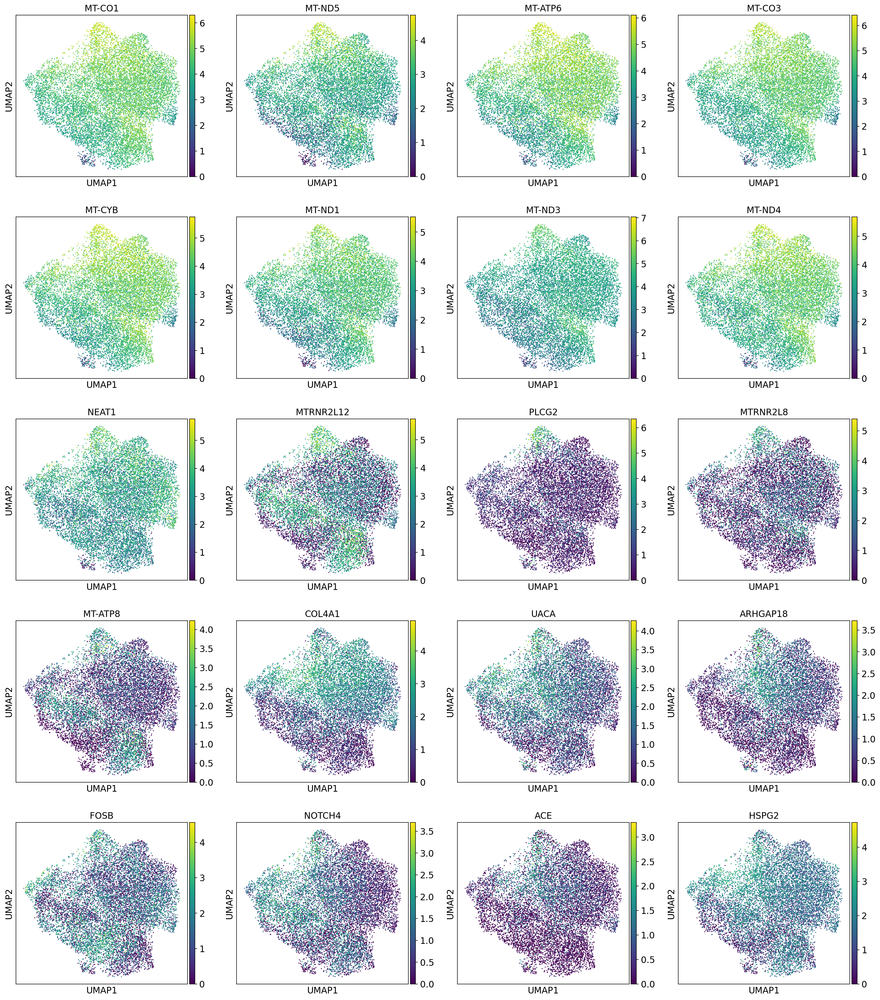

In [202]:
sc.pl.umap(adata_EC, color=deg_non_mixing_EC_cl_genes_used_for_mapping[:20])

<Axes: xlabel='leiden_EC'>

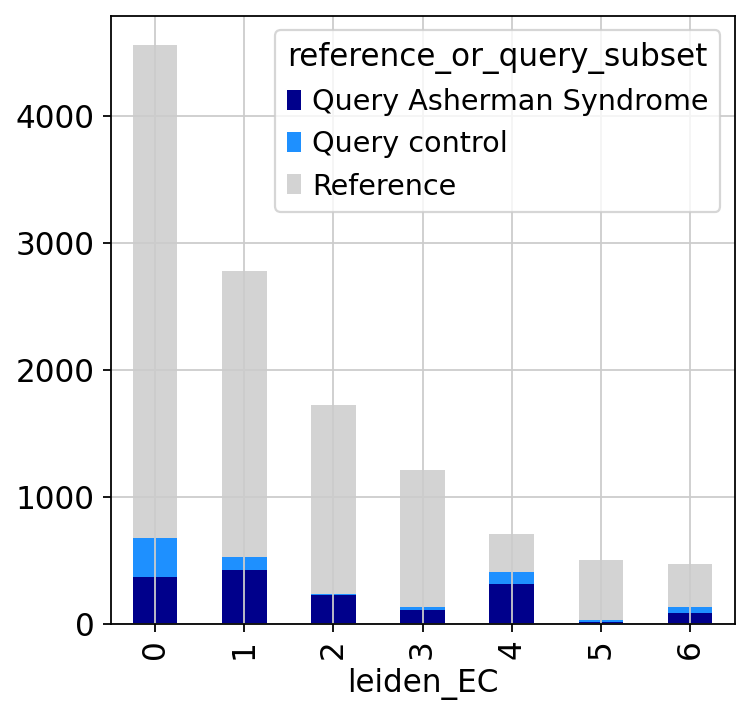

In [205]:
pd.crosstab(adata_EC.obs.leiden_EC, adata_EC.obs.reference_or_query_subset).plot(
    kind="bar", stacked=True, color=palette_ref_q
)

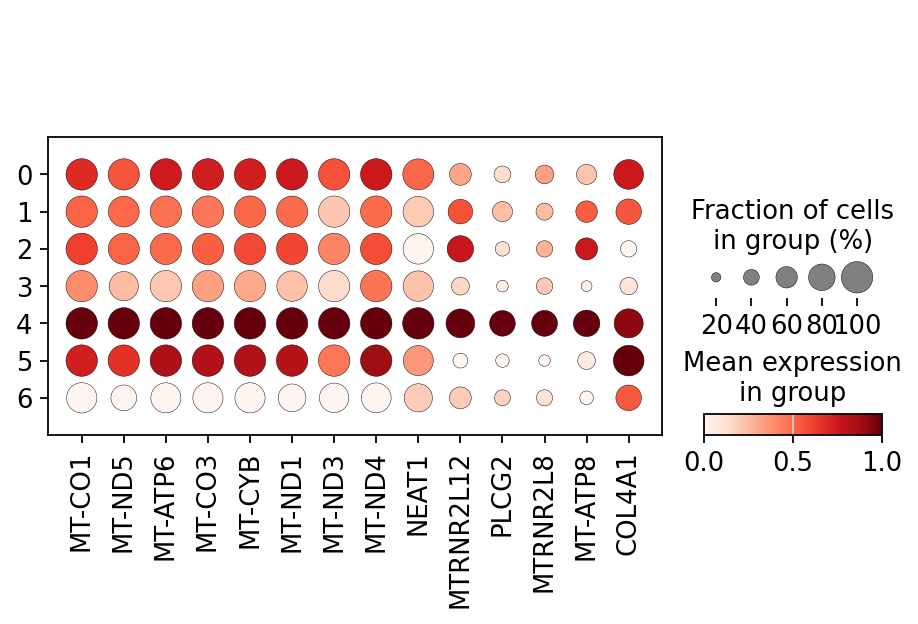

In [222]:
sc.pl.dotplot(
    adata_EC,
    groupby="leiden_EC",
    var_names=deg_non_mixing_EC_cl_genes_used_for_mapping[:14],
    standard_scale="var",
)

In [208]:
# sc.pl.umap(adata_full, color=["PLCG2", "reference_or_query"])

In [223]:
adata_full.obs["reference_or_query_subset"] = adata_emb.obs.loc[
    adata_full.obs.index, "reference_or_query_subset"
]
adata_full.obs["leiden_group"] = [
    f"{cl} ({gr})"
    for cl, gr in zip(adata_full.obs.leiden, adata_full.obs.reference_or_query_subset)
]
adata_full.obs["group_leiden"] = [
    f"{cl} ({gr})"
    for cl, gr in zip(adata_full.obs.reference_or_query_subset, adata_full.obs.leiden)
]

In [217]:
[
    gene
    for gene in deg_non_mixing_EC_cl_genes_used_for_mapping[:20]
    if not gene.startswith("MT-")
]

['NEAT1',
 'MTRNR2L12',
 'PLCG2',
 'MTRNR2L8',
 'COL4A1',
 'UACA',
 'ARHGAP18',
 'FOSB',
 'NOTCH4',
 'ACE',
 'HSPG2']

In [219]:
batch_genes = ["NEAT1", "MTRNR2L12", "PLCG2", "MTRNR2L8", "COL4A1", "FOSB"]

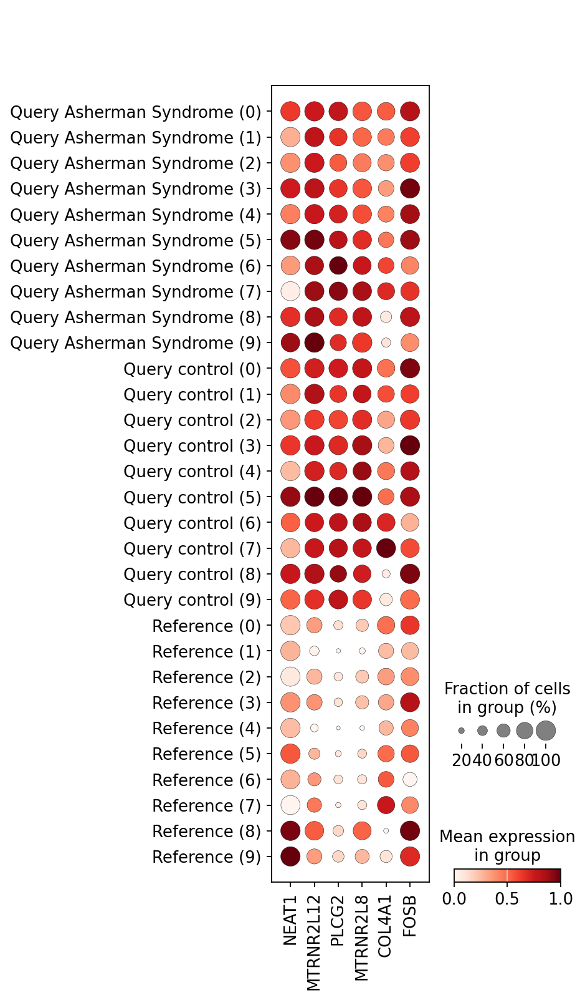

In [224]:
sc.pl.dotplot(
    adata_full[adata_full.obs.leiden.isin(range(10)), :],
    groupby="group_leiden",
    var_names=batch_genes,
    standard_scale="var",
)